In [231]:
# for auto-reloading external modules
%load_ext autoreload
%autoreload 2

import numpy as np
from matplotlib import pyplot as plt
from matplotlib.collections import LineCollection
from mpl_toolkits.mplot3d.art3d import Line3DCollection
from scipy.io import loadmat
import glob
import h5py
from scipy.stats import pearsonr
import torch
from torch import nn
from sklearn.metrics import roc_curve, precision_recall_curve, auc
from sklearn.metrics.pairwise import cosine_similarity
from scipy.stats import binned_statistic
import pandas as pd
import pickle
import re
from datetime import datetime
import seaborn as sns

import os
import sys
# sys.path.append('/mnt/scratch09/yongrong/projects/bat-intelligence/src/digitalbat')
sys.path.append(os.path.expanduser('~/Documents/code/digitalbat')) 
from digitalbat.datasets.data import bat_data_loader
from digitalbat.models.former import Bat_Transformer
from digitalbat.models.glm import Bat_GLM
from digitalbat.models.layers import ELU1, TransformerEncoderRoPE
from digitalbat.training.trainer import bat_former_trainer
from digitalbat.utility.utils import auprc_per_unit, corr, interpolate_signal_with_nans, lowpass_filter, \
                                    corr, poisson_fraction_deviance_explained, poisson_fde_population, generate_2d_rate_map
from digitalbat.utility.utils import set_random_state, plot_2d_rate_map, plot_2d_trajectory_response, plot_2d_trajectory_response_multiple, \
                                    plot_3d_trajectory, resample_response, nearest_neighbor_score, OrthogonalityPermutationTest
from digitalbat.datasets.data import Data_Prep_for_Raw, bat_data_loader
from digitalbat.utility.interpreter import Saliency, PermutationImportance, ActivationMaximization, ShapAnalysis, Gradient_Bat_Transformer # IntegGradi
from digitalbat.utility.TrajectoryRF import Generate_Synthetic_Trajecories, Time_Resolved_TRF, Time_Resolved_Phase, Trajectory_Level_TRF

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [232]:
seed = 1
set_random_state(seed)

device = 'cuda'

# Dataloader

In [234]:
# recorded data
data_config = dict(
    use_speed_head_dir = False, # False
    use_IMU_flag = False,  # False
    use_click_flag = False, # False
    use_LFP_flag = False,  # False
    use_ripple_flag = False,
    only_flight_flag = True,  # True
    no_3d_location = False, # False
    spike_count_flag = True,
    bin_width = 0.10, # 0.10, in seconds
    split_flights_for_train = 'random', # the way to split flight paths for train + valid + test; either 'manual' or 'random'
    type_train_num = 1,  # 1; for splitting flight clustering data
    type_valid_num = 1,  # 1; for splitting flight clustering data
    special_id_count_thresh = 3,  # 3; for splitting flight clustering data
    only_use_special_id_4train_flag = False,  # False
    shuffle_flag = True, # False; shuffle the training data
    time_shuffle_for_trajecotry_flag = False,
    simulate_place_cell_flag = False, # False
    split_each_trajectory_flag = True,  # True
    window_size = None, # 20, None; for splitting each trajectory into multiple samples
    stride_train = None, # 20, None; splitting each trajectory into multiple samples, for training data
    stride_test = None, # 20, None; splitting each trajectory into multiple samples, for test data
    batch_size_train = None, # None;
    batch_size_test = None, # None;
    session_names = [
        'Dataset_3_14543_240419',
        'Dataset_3_14543_240420',
        'Dataset_3_14543_240421',
        'Dataset_3_29959_240402',
        'Dataset_3_29959_240403',
        'Dataset_3_29959_240404',
        'Dataset_2_14445_231208',
        'Dataset_2_14445_231209', # only 9 flight trajectory types
        'Dataset_1_32622_231009',
        'Dataset_1_32622_231010',  # only ~50 units
    ],
    parent_folder = '/mnt/s5/Adam/Angelo/NP_datasets/',
)
dataloaders, behavior_dim, unit_num_dict, meta_info_dict = bat_data_loader(**data_config)

dataloaders, behavior_dim, unit_num_dict

({'train': {'Dataset_3_14543_240419': <torch.utils.data.dataloader.DataLoader at 0x7f754ffefa50>,
   'Dataset_3_14543_240420': <torch.utils.data.dataloader.DataLoader at 0x7f754ffefc50>,
   'Dataset_3_14543_240421': <torch.utils.data.dataloader.DataLoader at 0x7f755dce0550>,
   'Dataset_3_29959_240402': <torch.utils.data.dataloader.DataLoader at 0x7f755dce0850>,
   'Dataset_3_29959_240403': <torch.utils.data.dataloader.DataLoader at 0x7f755dce0b50>,
   'Dataset_3_29959_240404': <torch.utils.data.dataloader.DataLoader at 0x7f755dce0e50>,
   'Dataset_2_14445_231208': <torch.utils.data.dataloader.DataLoader at 0x7f755dce1150>,
   'Dataset_2_14445_231209': <torch.utils.data.dataloader.DataLoader at 0x7f755dce1450>,
   'Dataset_1_32622_231009': <torch.utils.data.dataloader.DataLoader at 0x7f755dce1750>,
   'Dataset_1_32622_231010': <torch.utils.data.dataloader.DataLoader at 0x7f755dce1a50>},
  'valid': {'Dataset_3_14543_240419': <torch.utils.data.dataloader.DataLoader at 0x7f754ffefb50>,
  

In [80]:
for session_name, session_data in dataloaders['train'].items():
    print(session_name, session_data)
    for batch_id, batch in enumerate(session_data):
        if not data_config['split_each_trajectory_flag']:
            print(batch[0].shape, batch[1].shape) # (N, behavior_feature), (N, spiking_unit_number)
        else:
            # behavior (N, window_size, behavior_feature), spike (N, window_size, spiking_unit_number), mask (N, window_size)
            print(batch[0].shape, batch[1].shape, batch[2].shape, np.sum(batch[2].detach().cpu().numpy()*1.0)) 

Dataset_3_14543_240419 <torch.utils.data.dataloader.DataLoader object at 0x7f75ae826d50>
torch.Size([25, 119, 3]) torch.Size([25, 119, 289]) torch.Size([25, 119]) 755.0
Dataset_3_14543_240420 <torch.utils.data.dataloader.DataLoader object at 0x7f757561b650>
torch.Size([95, 97, 3]) torch.Size([95, 97, 126]) torch.Size([95, 97]) 2380.0
Dataset_3_14543_240421 <torch.utils.data.dataloader.DataLoader object at 0x7f757561bc50>
torch.Size([78, 61, 3]) torch.Size([78, 61, 100]) torch.Size([78, 61]) 1964.0
Dataset_3_29959_240402 <torch.utils.data.dataloader.DataLoader object at 0x7f755deac550>
torch.Size([107, 81, 3]) torch.Size([107, 81, 317]) torch.Size([107, 81]) 3301.0
Dataset_3_29959_240403 <torch.utils.data.dataloader.DataLoader object at 0x7f755deac850>
torch.Size([91, 73, 3]) torch.Size([91, 73, 191]) torch.Size([91, 73]) 2493.0
Dataset_3_29959_240404 <torch.utils.data.dataloader.DataLoader object at 0x7f755deacb50>
torch.Size([55, 65, 3]) torch.Size([55, 65, 190]) torch.Size([55, 65]) 

In [81]:
tier = 'train'
session_name = list(dataloaders[tier].keys())[0]
for ii, batch in enumerate(dataloaders[tier][session_name]):
    if not data_config['split_each_trajectory_flag']:
        print(batch[0].shape, batch[1].shape) 
    else:
        print(batch[0].shape, batch[1].shape, batch[2].shape) # torch.Size([61, 20, 3]) torch.Size([61, 20, 289]) torch.Size([61, 20])
# get the elements at real timesteps
tempbeha = batch[0].detach().cpu().numpy()
tempspik = batch[1].detach().cpu().numpy()
tempmask = batch[2].detach().cpu().numpy()
print(tempbeha.shape, tempspik.shape) # (61, 20, 3) (61, 20, 289)
tempbeha = tempbeha[tempmask ==1]
tempspik = tempspik[tempmask ==1]
print(tempbeha.shape, tempspik.shape) # (981, 3) (981, 289)

torch.Size([25, 119, 3]) torch.Size([25, 119, 289]) torch.Size([25, 119])
(25, 119, 3) (25, 119, 289)
(755, 3) (755, 289)


In [82]:
batch._fields, batch.flight_path_index, batch.flight_type_index

(('behavior', 'spike', 'mask', 'flight_path_index', 'flight_type_index'),
 tensor([26., 18., 23.,  6.,  8., 28., 19.,  9., 21.,  2.,  7.,  3., 15., 36.,
         14., 22., 16., 27., 13., 34., 32., 31., 30.,  0., 25.]),
 tensor([10.,  9.,  9.,  3.,  3., 12.,  9.,  3.,  9.,  2.,  3.,  3.,  7., 21.,
          6.,  9.,  8., 11.,  5., 19., 17., 16., 15.,  1., 10.]))

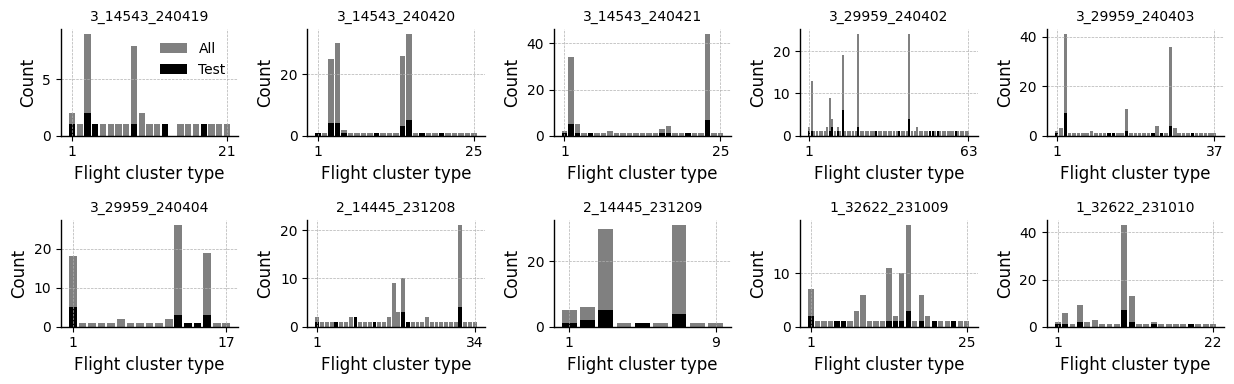

In [83]:
# summarize the flight cluster type distribution
session_names = list(dataloaders['test'].keys())
ncols = 5
nrows = len(session_names) // ncols
fig, axes = plt.subplots(nrows=nrows, ncols=ncols,figsize=(ncols*2.5,nrows*2))
for ii in range(nrows):
    for jj in range(ncols):
        session_name = list(dataloaders['test'].keys()) [ii * ncols + jj]
        flight_type_train = dataloaders['train'][session_name].dataset.flight_type_index.detach().cpu().numpy()
        flight_type_valid = dataloaders['valid'][session_name].dataset.flight_type_index.detach().cpu().numpy()
        flight_type_test = dataloaders['test'][session_name].dataset.flight_type_index.detach().cpu().numpy()
        flight_type = np.concatenate((flight_type_train, flight_type_valid, flight_type_test))
        unique_vals, counts = np.unique(flight_type, return_counts=True)
        unique_vals_test, counts_test = np.unique(flight_type_test, return_counts=True)
        axes[ii,jj].bar(unique_vals, counts, color='gray', label='All')
        axes[ii,jj].bar(unique_vals_test, counts_test, color='k', label='Test')
        axes[ii,jj].set_xticks([1, unique_vals.max()])
        axes[ii,jj].set_xlabel("Flight cluster type")
        axes[ii,jj].set_ylabel("Count")
        axes[ii,jj].set_title(f'{session_name[8:]}', fontsize=10)
axes[0,0].legend(loc='best',frameon=False)
plt.tight_layout()

# Transformer model

In [85]:
model_config = dict(
    input_dim = behavior_dim,
    output_dim_dict=unit_num_dict, 
    # place
    use_place_as_input=False, # add spatial basis
    spatial_centers_sigma_dict=meta_info_dict['spatial_centers_sigma'],
    latent_dim_place = 32,
    # trajectory
    use_trajectory_as_input=True,
    latent_dim = 32, # 256
    ff_dim = 32, # 256
    num_heads = 4, # 4
    num_layers = 1, # 1
    dropout_prob = 0.3, # 0.7
    #
    # use_low_rank = True, # low rank matrix multiplication
    # use_low_rank_readout = True, # low rank for readouts
    # low_rank_r = 4, # 4
    final_activation=ELU1(), # nn.Identity(),
)
bat_former = Bat_Transformer(**model_config)

bat_former

Bat_Transformer(
  (embed_traj): Linear(in_features=3, out_features=32, bias=True)
  (embed_traj_dropout): Dropout(p=0.1, inplace=False)
  (layers): ModuleList(
    (0): TransformerEncoderRoPE(
      (attention): MultiheadAttentionRoPE(
        (W_q): Linear(in_features=32, out_features=32, bias=True)
        (W_k): Linear(in_features=32, out_features=32, bias=True)
        (W_v): Linear(in_features=32, out_features=32, bias=True)
        (W_o): Linear(in_features=32, out_features=32, bias=True)
      )
      (ff): Sequential(
        (0): Linear(in_features=32, out_features=32, bias=True)
        (1): GELU(approximate='none')
        (2): Linear(in_features=32, out_features=32, bias=True)
      )
      (dropout): Dropout(p=0.3, inplace=False)
      (norm1): LayerNorm((32,), eps=1e-05, elementwise_affine=True)
      (norm2): LayerNorm((32,), eps=1e-05, elementwise_affine=True)
    )
  )
  (readouts): ModuleDict(
    (Dataset_3_14543_240419): Sequential(
      (0): Linear(in_features=32

# Training

Testing weight_decay=0


Training:   0%|          | 0/1000 [00:00<?, ?it/s]

Training:  21%|██        | 210/1000 [00:48<03:03,  4.31it/s]


Early stopping at epoch 211 (no improvement for 20 epochs)
  Final val score (median FDE, filtered): 0.0537
Testing weight_decay=1e-05


Training:   3%|▎         | 33/1000 [00:08<03:57,  4.08it/s]


...

Early stopping at epoch 51 (no improvement for 20 epochs)
  Final val score (median FDE, filtered): 0.0623
Testing weight_decay=0.01


Training:   4%|▍         | 42/1000 [00:09<03:34,  4.46it/s]


Early stopping at epoch 43 (no improvement for 20 epochs)
  Final val score (median FDE, filtered): 0.0649
Testing weight_decay=0.1


Training:   3%|▎         | 30/1000 [00:07<03:55,  4.12it/s]

Early stopping at epoch 31 (no improvement for 20 epochs)
  Final val score (median FDE, filtered): 0.0642

Best weight_decay: 0.01 with val score: 0.0649


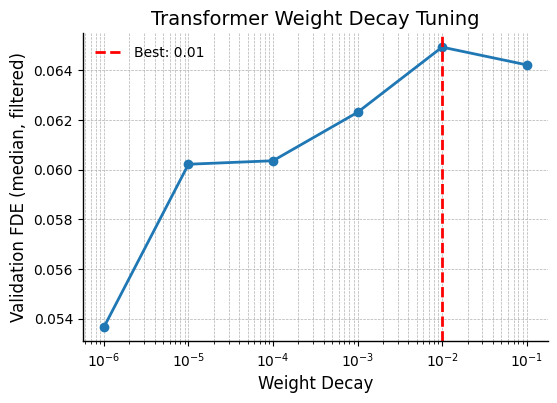

In [ ]:
# Hyperparameter tuning for weight_decay using validation set
from copy import deepcopy

weight_decay_candidates = [0, 1e-5, 1e-4, 1e-3, 1e-2, 1e-1]

best_wd_transformer = None
best_val_score_transformer = -np.inf
best_weights_transformer = None
wd_results_transformer = []

for wd in weight_decay_candidates:
    print(f'Testing weight_decay={wd}')
    
    # Create model, warm-start from previous best if available
    bat_former_tune = Bat_Transformer(**model_config)
    if best_weights_transformer is not None:
        bat_former_tune.load_state_dict(deepcopy(best_weights_transformer))
    
    # Train with this weight_decay
    tune_config = dict(
        model=bat_former_tune,
        dataloaders=dataloaders,
        device=device,
        is_causal=False,
        is_bigbird=False,
        attention_window_size=9,
        num_global=2,
        n_epochs=1000,
        lr=0.01,
        weight_decay=wd,
        loss_fn=nn.PoissonNLLLoss(log_input=False),
        valid_fn=poisson_fde_population,
        valid_stat='median',
        early_stopping_patience=100,
        save_model=False,
    )
    val_score, weights, val_scores = bat_former_trainer(**tune_config)
    wd_results_transformer.append({'weight_decay': wd, 'val_score': val_score})
    print(f'  Final val score (median FDE, filtered): {val_score:.4f}')
    
    if val_score > best_val_score_transformer:
        best_val_score_transformer = val_score
        best_wd_transformer = wd
        best_weights_transformer = deepcopy(weights)

print(f'\nBest weight_decay: {best_wd_transformer} with val score: {best_val_score_transformer:.4f}')

# Plot results
fig, ax = plt.subplots(figsize=(6, 4))
wds = [r['weight_decay'] for r in wd_results_transformer]
scores = [r['val_score'] for r in wd_results_transformer]
ax.semilogx([w if w > 0 else 1e-6 for w in wds], scores, 'o-')
ax.axvline(best_wd_transformer if best_wd_transformer > 0 else 1e-6, color='r', linestyle='--', label=f'Best: {best_wd_transformer}')
ax.set_xlabel('Weight Decay')
ax.set_ylabel('Validation FDE (median, filtered)')
ax.set_title('Transformer Weight Decay Tuning')
ax.legend()
plt.show()

In [ ]:
# Set best_wd_transformer here if skipping tuning loop
best_wd_transformer = best_wd_transformer if 'best_wd_transformer' in dir() else 0.0

# Train final Transformer with best weight_decay
bat_former = Bat_Transformer(**model_config)  # Fresh model

trainer_config = dict(
    model=bat_former,
    dataloaders=dataloaders,
    device=device,
    is_causal=False,
    is_bigbird=False,
    attention_window_size=9,
    num_global=2,
    n_epochs=1000,
    lr=0.01,
    weight_decay=best_wd_transformer,
    loss_fn=nn.PoissonNLLLoss(log_input=False),
    valid_fn=poisson_fde_population,
    valid_stat='median',
    early_stopping_patience=100,
    save_model=True,
    model_name=f'./out/bat_former_seed_{seed}_wd_{best_wd_transformer}.pth',
)

# best_acc, best_weights, acc_vals = bat_former_trainer(**trainer_config)
# print(f'Final model trained with weight_decay={best_wd_transformer}, best val score: {best_acc:.4f}')

# fig, axes = plt.subplots(nrows=1, ncols=1, figsize=(4, 3))
# axes.plot(acc_vals)
# axes.set_title(f"Best: {best_acc:.4f}")
# axes.set_xlabel("Epoch")
# axes.set_ylabel("FDE (median, filtered)")
# plt.show()

# Evaluation

In [131]:
def evaluate_model(model, dataloaders, valid_fn, device, flight_filter=None, meta_info_dict=None):
    """
    Evaluate model on test data.
    
    Args:
        model: trained model in eval mode
        dataloaders: dict with 'test' key
        valid_fn: function(y_true, y_pred) -> scores array
        device: torch device
        flight_filter: None (all), 'ood', or 'indomain'
        meta_info_dict: required if flight_filter is not None
    
    Returns:
        dict mapping session_name -> scores array
    """
    results = {}
    model.eval()
    
    for session_name, session_data in dataloaders['test'].items():
        # Get flight type filter if needed
        if flight_filter == 'ood':
            target_types = np.array(meta_info_dict['flight_type_test_ood'][session_name], dtype=int)
            if target_types.size == 0:
                results[session_name] = np.array([])
                continue
        elif flight_filter == 'indomain':
            target_types = np.array(meta_info_dict['flight_type_test_indomain'][session_name], dtype=int)
        else:
            target_types = None
        
        y_val_list, y_pred_list = [], []
        for batch in session_data:
            X_val = batch.behavior.to(device)
            y_val = batch.spike.to(device)
            mask_val = batch.mask.to(device)
            
            # Filter by flight type if needed
            if target_types is not None:
                batch_mask = np.isin(batch.flight_type_index.numpy(), target_types)
                if not batch_mask.any():
                    continue
                X_val = X_val[batch_mask]
                y_val = y_val[batch_mask]
                mask_val = mask_val[batch_mask]
            
            y_pred = model(session_name, X_val, mask_val)
            y_val_list.append(y_val[mask_val == 1.0].detach().cpu().numpy())
            y_pred_list.append(y_pred[mask_val == 1.0].detach().cpu().numpy())
        
        if y_val_list:
            y_val_np = np.vstack(y_val_list)
            y_pred_np = np.vstack(y_pred_list)
            results[session_name] = valid_fn(y_val_np, y_pred_np)
        else:
            results[session_name] = np.array([])
    
    return results

In [132]:
# f'./out/bat_former_data_random_trajectory_input_seed_1.pth' # real data + trajectory input
# f'./out/bat_former_data_random_dual_input_seed_1.pth' # real data + dual-input model
# f'./out/bat_former_data_simulate_dual_input_seed_1.pth', # simulate place cell + dual-input model
# './out/bat_former_data_random_seed_1.pth' # f'./out/test.pth'
model_name = f'./out/bat_former_seed_{seed}_wd_{best_wd_transformer}.pth'

In [218]:
# Load trained model
bat_former.load_state_dict(torch.load(model_name, map_location=device))
bat_former = bat_former.to(device)

# Define metrics and filters to evaluate
metrics = {
    'corr': lambda y_true, y_pred: corr(y_true, y_pred, axis=0),
    'fde': lambda y_true, y_pred: poisson_fde_population(y_true, y_pred),
}
flight_filters = [None, 'ood', 'indomain']  # None = all flights

# Evaluate all combinations
transformer_results = {}
for metric_name, valid_fn in metrics.items():
    for flight_filter in flight_filters:
        key = f"{metric_name}_{flight_filter or 'all'}"
        transformer_results[key] = evaluate_model(
            bat_former, dataloaders, valid_fn, device,
            flight_filter=flight_filter, meta_info_dict=meta_info_dict
        )
        # Print summary
        all_scores = np.hstack([v for v in transformer_results[key].values() if len(v) > 0])
        stat = np.nanmedian if 'fde' in key else np.nanmean
        print(f"{key}: {stat(all_scores):.4f}")

corr_all: 0.2623
corr_ood: 0.1467
corr_indomain: 0.2800
fde_all: 0.0834
fde_ood: -0.0900
fde_indomain: 0.1026


## Corr. vs. FDE

In [134]:
# Corr. vs. FDE
if False:
    ncols = 5
    nrows = len(list(dataloaders['test'].keys())) // ncols
    fig, axes = plt.subplots(nrows=nrows, ncols=ncols,figsize=(ncols*2.5,nrows*2))
    for ii in range(nrows):
        for jj in range(ncols):
            session_name = list(dataloaders['test'].keys()) [ii * ncols + jj]
            axes[ii,jj].scatter(corr_dict[session_name], fde_dict[session_name], color='k', s=1)
            axes[ii,jj].set_ylim(-1.0, 1)
            axes[ii,jj].set_xlabel('Corr.')
            axes[ii,jj].set_ylabel('FDE')
            axes[ii,jj].set_title(f'{session_name[8:]}', fontsize=10)
    plt.tight_layout()

## Rate map

session_target: Dataset_3_29959_240403


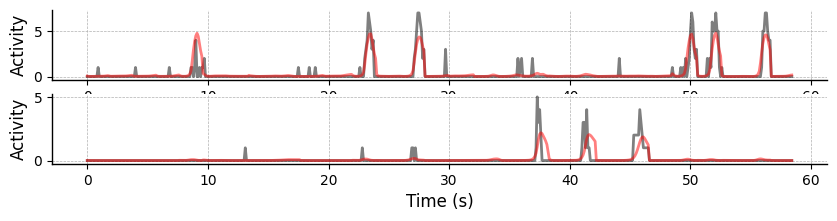

In [135]:
session_target = list(dataloaders['test'].keys())[4]
print(f'session_target: {session_target}')
bat_former.load_state_dict(torch.load(model_name, map_location=device))
# bat_former.load_state_dict(best_weights)
bat_former = bat_former.to(device)
bat_former.eval()
for session_name, session_data in dataloaders['test'].items():
    # print(session_name, session_data)
    if session_name == session_target:
        X_val_np_list = []
        y_val_np_list = []
        y_pred_np_list = []
        for batch_id, batch in enumerate(session_data):
            X_val = batch[0].to(device)
            y_val = batch[1].to(device)
            mask_val = batch[2].to(device)
            y_pred = bat_former(
                session_name, 
                X_val, 
                mask_val, 
                is_causal=trainer_config['is_causal'], 
                is_bigbird=trainer_config['is_bigbird'], 
                attention_window_size=trainer_config['attention_window_size'],
                num_global=trainer_config['num_global'],
            )
            X_val_np = X_val.detach()[mask_val == 1.0].cpu().numpy()
            y_val_np = y_val.detach()[mask_val == 1.0].cpu().numpy() 
            y_pred_np = y_pred.detach()[mask_val == 1.0].cpu().numpy()
            # print(f'X_val_np.shape: {X_val_np.shape}, y_val_np.shape: {y_val_np.shape}')
            X_val_np_list.append(X_val_np)
            y_val_np_list.append(y_val_np)
            y_pred_np_list.append(y_pred_np)
        X_val_np = np.vstack(X_val_np_list)
        y_val_np = np.vstack(y_val_np_list)
        y_pred_np = np.vstack(y_pred_np_list)
        # print(f'X_val_np.shape: {X_val_np.shape}, y_val_np.shape: {y_val_np.shape}')
        temp_scores = valid_fn(y_val_np, y_pred_np) # an array of scores for spiking units in one batch data within one session of data

ccs = np.copy(temp_scores)

temps = np.arange(-1, -3, -1).tolist() 
num = y_val_np.shape[0]
nrows = len(temps)
fig, ax = plt.subplots(nrows=nrows, ncols=1, figsize=(10, nrows))
for ii in range(nrows):
    temp = np.argsort(ccs)[temps[ii]]
    ax[ii].plot(np.arange(num) * data_config['bin_width'], y_val_np[:num, temp], color='k', alpha=0.5)
    ax[ii].plot(np.arange(num) * data_config['bin_width'], y_pred_np[:num,temp], color='red', alpha=0.5)
    ax[ii].set_xlabel("Time (s)") 
    ax[ii].set_ylabel("Activity")

In [136]:
print(f'session_target: {session_target}')
bat_former.load_state_dict(torch.load(model_name, map_location=device))
# bat_former.load_state_dict(best_weights)
bat_former = bat_former.to(device)
bat_former.eval()
for session_name, session_data in dataloaders['test'].items():
    # print(session_name, session_data)
    if session_name == session_target:
        X_val_np_list = []
        y_val_np_list = []
        y_pred_np_list = []
        mask_val_list = []
        flight_path_index_list = []
        flight_type_index_list = []
        for batch_id, batch in enumerate(session_data):
            X_val = batch.behavior.to(device)
            y_val = batch.spike.to(device)
            mask_val = batch.mask.to(device)
            y_pred = bat_former(
                session_name, 
                X_val, 
                mask_val, 
                is_causal=trainer_config['is_causal'], 
                is_bigbird=trainer_config['is_bigbird'], 
                attention_window_size=trainer_config['attention_window_size'],
                num_global=trainer_config['num_global'],
            )
            X_val_np = X_val.detach().cpu().numpy()
            y_val_np = y_val.detach().cpu().numpy() 
            y_pred_np = y_pred.detach().cpu().numpy()
            mask_val_np = mask_val.detach().cpu().numpy()
            flight_path_index_np = batch.flight_path_index.detach().cpu().numpy()
            flight_type_index_np = batch.flight_type_index.detach().cpu().numpy()
            #
            X_val_np_list.append(X_val_np)
            y_val_np_list.append(y_val_np)
            y_pred_np_list.append(y_pred_np)
            mask_val_list.append(mask_val_np)
            flight_path_index_list.append(flight_path_index_np)
            flight_type_index_list.append(flight_type_index_np)
X_val_np = np.vstack(X_val_np_list)
y_val_np = np.vstack(y_val_np_list)
y_pred_np = np.vstack(y_pred_np_list)
mask_val = np.vstack(mask_val_list)
flight_path_index = np.hstack(flight_path_index_list) # use hstack for stacking 1D arrays
flight_type_index = np.hstack(flight_type_index_list) # use hstack for stacking 1D arrays
print(f'X_val_np.shape: {X_val_np.shape}, y_val_np.shape: {y_val_np.shape}, y_pred_np.shape: {y_pred_np.shape}, mask_val.shape: {mask_val.shape}')
# X_val_np.shape: (64, 68, 3), y_val_np.shape: (64, 68, 168), y_pred_np.shape: (64, 68, 168), mask_val.shape: (64, 68),... 64 batches, 68 time points, 168 neurons
print(f'flight_path_index.shape: {flight_path_index.shape}, flight_type_index.shape: {flight_type_index.shape}') # flight_path_index.shape: (64,), flight_type_index.shape: (64,)
print(f'flight_path_index: {flight_path_index}')
print(f'flight_type_index: {flight_type_index}')

session_target: Dataset_3_29959_240403
X_val_np.shape: (21, 73, 3), y_val_np.shape: (21, 73, 191), y_pred_np.shape: (21, 73, 191), mask_val.shape: (21, 73)
flight_path_index.shape: (21,), flight_type_index.shape: (21,)
flight_path_index: [ 38.  34.  15.  36. 103.   0.  56.  11.  42.  84.  63.  10.  33. 125.
  68.  76.  81. 102.  93.  57.   5.]
flight_type_index: [ 3.  3.  3.  3. 27.  1. 13.  3.  3. 27. 17.  3.  3. 32. 17. 23. 25. 27.
 27. 14.  3.]


session_target: Dataset_3_29959_240403


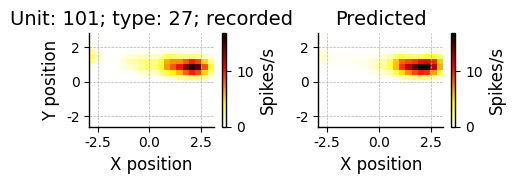

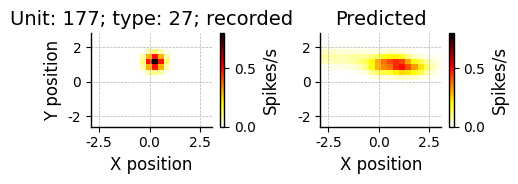

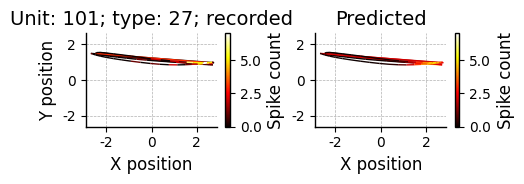

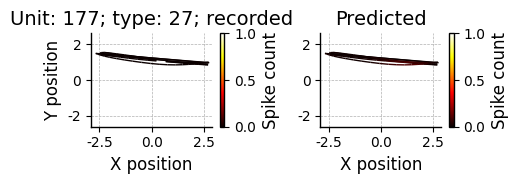

In [137]:
print(f'session_target: {session_target}')
target_type = 27
target_ind = np.where(flight_type_index == target_type)[0]
#
target_X_val = X_val_np[target_ind, :, :]
target_y_val = y_val_np[target_ind, :, :]
target_y_pred = y_pred_np[target_ind, :, :]
target_mask_val = mask_val[target_ind, ]
#
target_X_val = target_X_val[target_mask_val == 1.0]
target_y_val = target_y_val[target_mask_val == 1.0]
target_y_pred = target_y_pred[target_mask_val == 1.0]
# print(f'target_X_val.shape: {target_X_val.shape}, target_y_val.shape: {target_y_val.shape}, target_y_pred.shape: {target_y_pred.shape}')
# target_X_val.shape: (1512, 3), target_y_val.shape: (1512, 168), target_y_pred.shape: (1512, 168) # 168 neurons
loc_xx = target_X_val[:, 0] * meta_info_dict['behavior_std'][session_target][0, 0, 0] + meta_info_dict['behavior_mean'][session_target][0, 0, 0]
loc_yy = target_X_val[:, 1] * meta_info_dict['behavior_std'][session_target][0, 0, 1] + meta_info_dict['behavior_mean'][session_target][0, 0, 1]
loc_xx_lim = meta_info_dict['r_lim'][session_target][0, :]
loc_yy_lim = meta_info_dict['r_lim'][session_target][1, :]
loc_bin_width = 0.3 # the bin width for the location space
dt = np.copy(data_config['bin_width'])  # time interval for each data point (in seconds)
#
units = np.argsort(ccs)[-2:][::-1]
for unit in units:
    spike_count_val = target_y_val[:, unit]
    spike_count_pred = target_y_pred[:, unit]
    plot_2d_rate_map(
        unit=unit,
        target_type=target_type,
        loc_xx=loc_xx,
        loc_yy=loc_yy,
        spike_count_val=spike_count_val,
        spike_count_pred=spike_count_pred,
        loc_xx_lim=loc_xx_lim,
        loc_yy_lim=loc_yy_lim,
        loc_bin_width=loc_bin_width,
        dt=dt,
    )
for unit in units:
    spike_count_val = target_y_val[:, unit]
    spike_count_pred = target_y_pred[:, unit]
    plot_2d_trajectory_response(
        unit=unit,
        target_type=target_type,
        loc_xx=loc_xx,
        loc_yy=loc_yy,
        spike_count_val=spike_count_val,
        spike_count_pred=spike_count_pred,
        loc_xx_lim=loc_xx_lim,
        loc_yy_lim=loc_yy_lim,
    )

# Attention matrix

session_target: Dataset_3_29959_240403


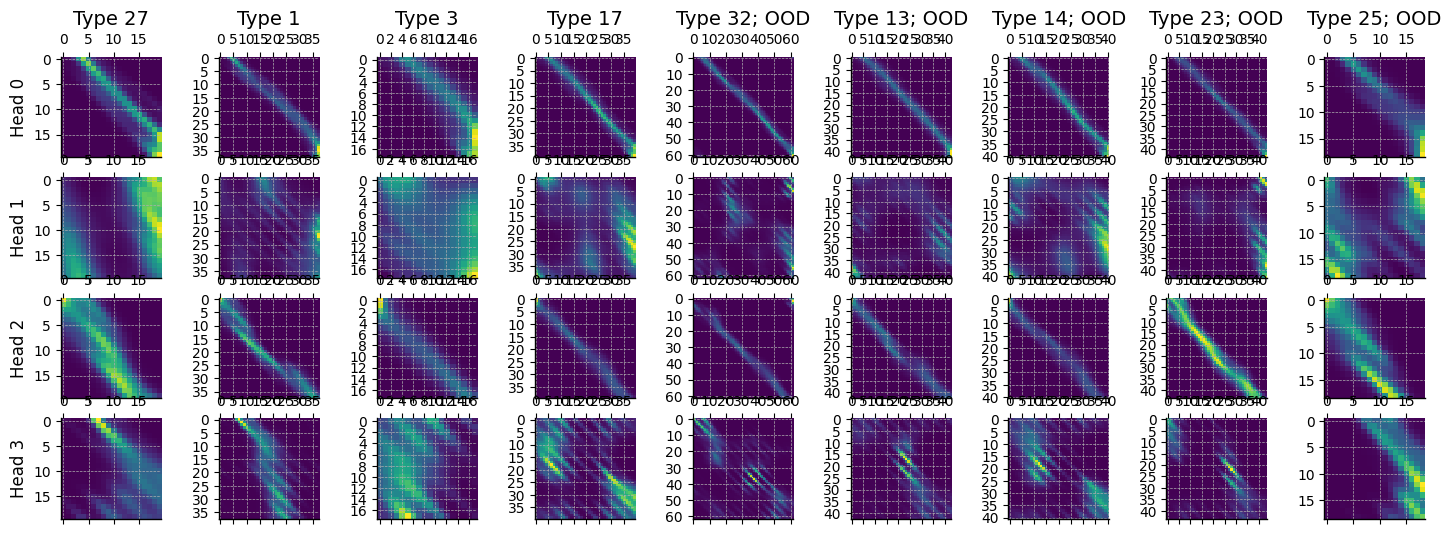

In [138]:
# Show attention weights for each flight cluster type within test data
session_target = list(dataloaders['test'].keys())[4]
print(f'session_target: {session_target}')
bat_former.load_state_dict(torch.load(model_name, map_location=device))
# bat_former.load_state_dict(best_weights)
bat_former = bat_former.to(device)
bat_former.eval()
for session_name, session_data in dataloaders['test'].items():
    # print(session_name, session_data)
    if session_name == session_target:
        # we have only one batch of test data
        for batch_id, batch in enumerate(session_data):
            X_val = batch[0].to(device)
            y_val = batch[1].to(device)
            mask_val = batch[2].to(device)
            flight_type_index = batch.flight_type_index.detach().cpu().numpy()
            y_pred, attn_weights_list = bat_former(
                session_name, 
                X_val, 
                mask_val, 
                is_causal=trainer_config['is_causal'], 
                is_bigbird=trainer_config['is_bigbird'], 
                attention_window_size=trainer_config['attention_window_size'],
                num_global=trainer_config['num_global'],
                return_attn_weights=True,
            )
            X_val_np = X_val.detach().cpu().numpy()
            mask_val_np = mask_val.detach().cpu().numpy()
attn_weights_list = [attn_weights.detach().cpu().numpy() for attn_weights in attn_weights_list]
target_types_indomain = np.array(meta_info_dict['flight_type_test_indomain'][session_target], dtype=int)
target_types_ood = np.array(meta_info_dict['flight_type_test_ood'][session_target], dtype=int)
target_types = np.concatenate((target_types_indomain, target_types_ood))

if True:
    nrows = attn_weights_list[0].shape[1]
    ncols = len(target_types_indomain) + len(target_types_ood)
    np.random.seed(1000)
    fig, ax = plt.subplots(nrows=nrows, ncols=ncols, figsize=(ncols*2, nrows*1.5))
    for ii in range(nrows):
        for jj in range(ncols):
            batch_ind, head_ind = np.where(flight_type_index == target_types[jj])[0][0], ii
            # only show the unmask elements (not padding ones)
            unmask_T = int(np.sum(mask_val.detach().cpu().numpy(), axis=1)[batch_ind])
            # plt.imshow(attn_weights_list[0][10,1])
            ax[ii,jj].matshow(attn_weights_list[0][batch_ind, head_ind][:unmask_T, :unmask_T])
        ax[ii,0].set_ylabel(f'Head {ii}')
    for jj in range(ncols):
        ax[0,jj].set_title(f'Type {target_types[jj]}' if target_types[jj] in target_types_indomain else f'Type {target_types[jj]}; OOD')

session_target: Dataset_3_29959_240403


Text(0, 0.5, 'Importance')

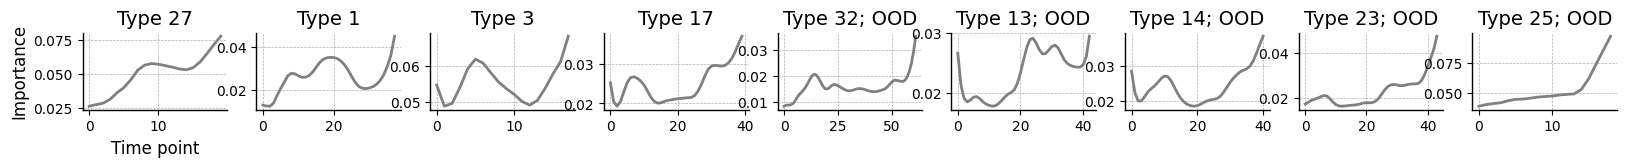

In [139]:
# For each attention matrix, we aggregate weights over the query axis and compute an importance score per time point
# that reflects its overall influence on the model's internal representation (i.e., how strongly the model attends to each position).
# we normalize the score by the length of the query (each flight path) and n_head
print(f'session_target: {session_target}')
ncols = len(target_types) 
nheads = attn_weights_list[0].shape[1] 
fig, ax = plt.subplots(nrows=1, ncols=ncols, figsize=(ncols*2.2, 1.0))
for ii in range(ncols): # for each flight cluster type
    inds = np.where(flight_type_index==target_types[ii])[0]
    temps = []
    for jj in range(1): # for each flight path: for jj in range(counts[ii]) # for now, we only use one flight path # TODO
        for kk in range(nheads): # for each attention head
            batch_ind, head_ind = inds[jj], kk
            # only show the unmask elements (not padding ones)
            unmask_T = int(np.sum(mask_val.detach().cpu().numpy(), axis=1)[batch_ind])
            temps.append(np.sum(attn_weights_list[0][batch_ind, head_ind][:unmask_T, :unmask_T], axis=0)/(unmask_T*nheads)) # sum across query
    temp = np.sum(np.array(temps), axis=0) # sum across heads and flight paths (belong to the same type)
    # ax[ii].bar(np.arange(len(temp)), temp, color='gray')
    ax[ii].plot(np.arange(len(temp)), temp, color='gray')
    ax[ii].set_title(f'Type {target_types[ii]}' if target_types[ii] in target_types_indomain else f'Type {target_types[ii]}; OOD')
ax[0].set_xlabel('Time point')
ax[0].set_ylabel('Importance')

session_target: Dataset_3_29959_240403


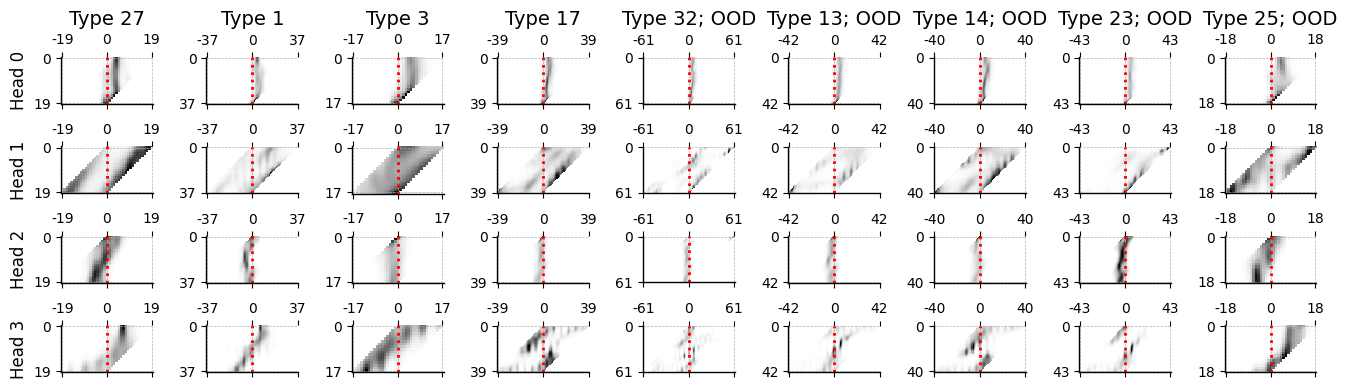

In [140]:
# For each time point, we reindex the attention matrix by a specific temporal offset relative to the query position, 
# producing a time-lag importance profile that quantifies how strongly each position attends to the past, present, and future. 
# This transformation enables direct comparison of temporal dependencies across all positions in the sequence.
from digitalbat.utility.utils import compute_shift_attention
print(f'session_target: {session_target}')
nrows = attn_weights_list[0].shape[1]
ncols = len(target_types)
np.random.seed(1000)
# batch_inds = np.where(flight_type_index==unique_flight_types[temp_ind])[0] # np.random.randint(0, attn_weights_list[0].shape[0], size = ncols)
fig, ax = plt.subplots(nrows=nrows, ncols=ncols, figsize=(ncols*1.5, nrows*1))
for ii in range(nrows):
    for jj in range(ncols):
        batch_ind, head_ind = np.where(flight_type_index==target_types[jj])[0][0], ii
        # only show the unmask elements (not padding ones)
        unmask_T = int(np.sum(mask_val.detach().cpu().numpy(), axis=1)[batch_ind])
        # plt.imshow(attn_weights_list[0][10,1])
        shift_attn = compute_shift_attention(attn_weights_list[0][batch_ind, head_ind][:unmask_T, :unmask_T])
        # ax[ii,jj].imshow(np.log10(shift_attn+1e-7), cmap='gray_r')
        ax[ii,jj].matshow(shift_attn, cmap='gray_r')
        ax[ii,jj].axvline(unmask_T-1, color='red', linestyle=':')
        ax[ii,jj].set_yticks([0, shift_attn.shape[0]-1])
        ax[ii,jj].set_xticks([0, unmask_T-1, shift_attn.shape[1]-1])
        ax[ii,jj].set_xticklabels([-(unmask_T-1), 0, unmask_T-1])
    ax[ii,0].set_ylabel(f'Head {ii}')
for jj in range(ncols):
    ax[0,jj].set_title(f'Type {target_types[jj]}' if target_types[jj] in target_types_indomain else f'Type {target_types[jj]}; OOD')
plt.tight_layout()

session_target: Dataset_3_29959_240403


Text(0, 0.5, 'Importance')

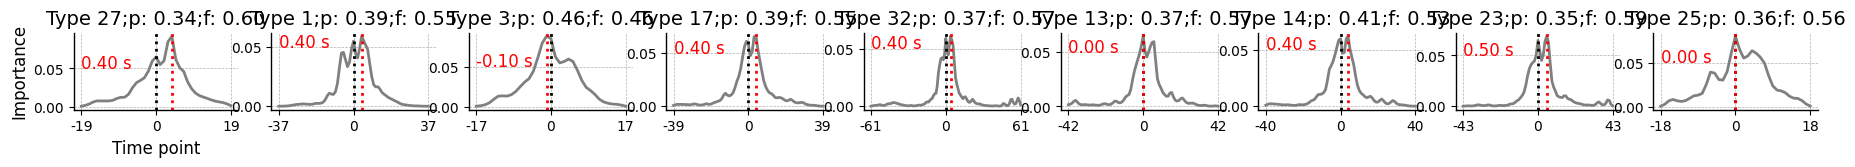

In [141]:
# For each shift attention matrix, we aggregate weights over the query axis and compute an importance score per time point
print(f'session_target: {session_target}')
ncols = len(target_types) 
nheads = attn_weights_list[0].shape[1] 
fig, ax = plt.subplots(nrows=1, ncols=ncols, figsize=(ncols*2.5, 1.0))
for ii in range(ncols): # for each flight cluster type
    inds = np.where(flight_type_index==target_types[ii])[0]
    temps = []
    for jj in range(1): # for each flight path: for jj in range(counts[ii]) # for now, we only use one flight path # TODO
        for kk in range(nheads): # for each attention head
            batch_ind, head_ind = inds[jj], kk
            # only show the unmask elements (not padding ones)
            unmask_T = int(np.sum(mask_val.detach().cpu().numpy(), axis=1)[batch_ind])
            shift_attn = compute_shift_attention(attn_weights_list[0][batch_ind, head_ind][:unmask_T, :unmask_T])
            temps.append(np.sum(shift_attn, axis=0)/(unmask_T*nheads)) # sum across query
    temp = np.sum(np.array(temps), axis=0) # sum across heads and flight paths (belong to the same type)
    # ax[ii].bar(np.arange(len(temp)), temp, color='gray')
    ax[ii].plot(np.arange(len(temp)), temp, color='gray')
    ax[ii].axvline(unmask_T-1, color='k', linestyle=':')
    ax[ii].axvline(np.argmax(temp), color='red', linestyle=':')
    ax[ii].text(0, 0.05, f"{(np.argmax(temp)-(unmask_T-1)) * data_config['bin_width']:.2f} s", color='red')
    ax[ii].set_xticks([0, unmask_T-1, shift_attn.shape[1]-1])
    ax[ii].set_xticklabels([-(unmask_T-1), 0, unmask_T-1])
    ax[ii].set_title(f'Type {target_types[ii]};p: {np.sum(temp[:unmask_T-1]):.2f};f: {np.sum(temp[unmask_T:]):.2f}')
ax[0].set_xlabel('Time point')
ax[0].set_ylabel('Importance')

session_target: Dataset_3_29959_240403


Text(0, 0.5, 'Query time')

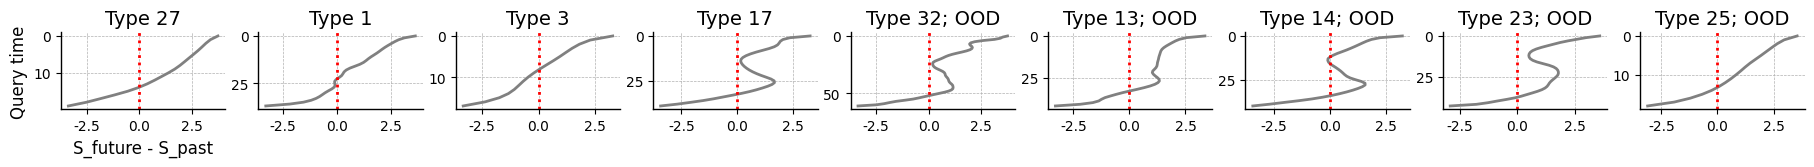

In [142]:
# For each (shift) attention, for each query time position, we aggregate scores over the key axis separately for the past and the future
# and then we subtract the past from the future. At the start of a flight, of course, it only attends to the future. The question is that
# when it starts to attend more to the past.
print(f'session_target: {session_target}')
ncols = len(target_types) 
nheads = attn_weights_list[0].shape[1] 
fig, ax = plt.subplots(nrows=1, ncols=ncols, figsize=(ncols*2.5, 1.0))
for ii in range(ncols): # for each flight cluster type
    inds = np.where(flight_type_index==target_types[ii])[0]
    temps = []
    for jj in range(1): # for each flight path: for jj in range(counts[ii]) # for now, we only use one flight path # TODO
        for kk in range(nheads): # for each attention head
            batch_ind, head_ind = inds[jj], kk
            # only show the unmask elements (not padding ones)
            unmask_T = int(np.sum(mask_val.detach().cpu().numpy(), axis=1)[batch_ind])
            shift_attn = compute_shift_attention(attn_weights_list[0][batch_ind, head_ind][:unmask_T, :unmask_T])
            temps.append(np.sum(shift_attn[:,unmask_T:],axis=1) - np.sum(shift_attn[:,:unmask_T-1], axis=1)) # (future - past) for each query time position 
    temp = np.sum(np.array(temps), axis=0) # sum across heads and flight paths (belong to the same type)
    # ax[ii].barh(np.arange(len(temp)), temp, color='gray')
    ax[ii].plot(temp, np.arange(len(temp)), color='gray')
    ax[ii].invert_yaxis()
    ax[ii].axvline(0.0, color='red', linestyle=':')
    ax[ii].set_title(f'Type {target_types[ii]}' if target_types[ii] in target_types_indomain else f'Type {target_types[ii]}; OOD')
ax[0].set_xlabel('S_future - S_past')
ax[0].set_ylabel('Query time')

session_target: Dataset_3_29959_240403


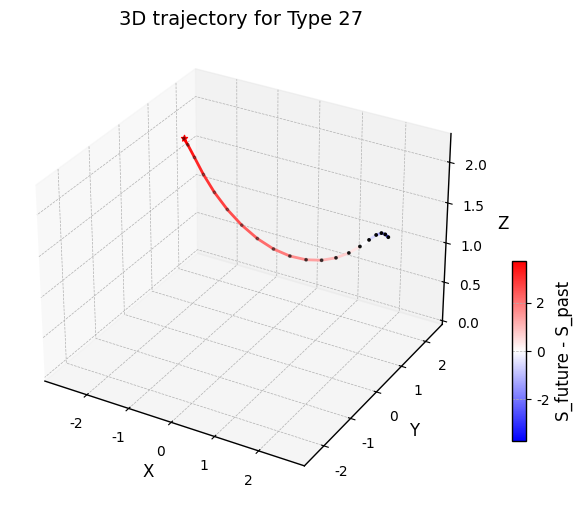

In [143]:
# Plot the 3d trajectory of one flight path (from each flight cluster type), colorized by S_future - S_past 
print(f'session_target: {session_target}')
nheads = attn_weights_list[0].shape[1] # attn_weights_list[0].shape: (64, 4, 68, 68) (batch_size, nheads, T, T)
for ii in range(1): # for ii in range(len(target_types)); for ii in range(1)
    inds = np.where(flight_type_index==target_types[ii])[0]
    for jj in range(1): # for flight paths belong to that type: for jj in range(len(inds)) # for now, we only use one flight path # TODO
        batch_ind = inds[jj]
        temps = []
        for kk in range(nheads): # for each attention head
            # only show the unmask elements (not padding ones)
            unmask_T = int(np.sum(mask_val_np, axis=1)[batch_ind]) # mask_val_np.shape: (64, 68) (batch_size, T)
            shift_attn = compute_shift_attention(attn_weights_list[0][batch_ind, kk][:unmask_T, :unmask_T])
            temps.append(np.sum(shift_attn[:,unmask_T:],axis=1) - np.sum(shift_attn[:,:unmask_T-1], axis=1)) # (future - past) for each query time position 
        s_fut_past = np.sum(np.array(temps), axis=0) # sum across heads 
    
        plot_config = dict(
            # X_val_np.shape: (64, 68, 3) (batch_size, T, 3)
            trajectory_3d = X_val_np[batch_ind][mask_val_np[batch_ind]==1.0,:] * meta_info_dict['behavior_std'][session_target][0,:,:] + meta_info_dict['behavior_mean'][session_target][0,:,:], 
            loc_lim = meta_info_dict['r_lim'][session_target], 
            flight_cluster_type = int(flight_type_index[batch_ind]),
            time_bin_width = data_config['bin_width'],
            visualize_array = s_fut_past, 
            cmap = 'bwr', 
            set_zero_as_medium = True,
            cax_ylabel = 'S_future - S_past', # colorbar ylabel
        )
        plot_3d_trajectory(
            **plot_config
        )

# Saliency

session_target: Dataset_3_29959_240403; target_neuron_index: 20; target_flight_type: 14


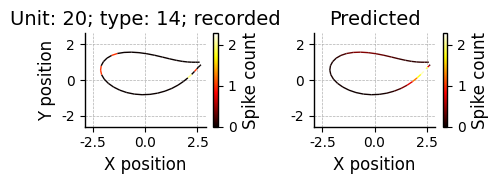

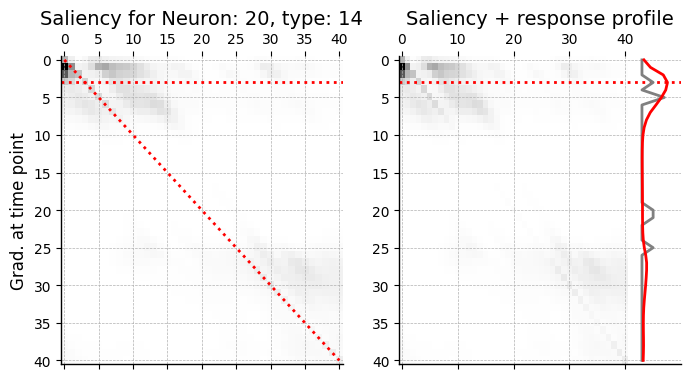

In [144]:
session_target = list(dataloaders['test'].keys())[4] # [4]
target_neuron_index = 20 # 139 # 177
# get the input (flight path) and its mask
target_flight_type = 14 # 32, 23
print(f'session_target: {session_target}; target_neuron_index: {target_neuron_index}; target_flight_type: {target_flight_type}')
for session_name, session_data in dataloaders['test'].items():
    # print(session_name, session_data)
    if session_name == session_target:
        # we have only one batch of test data
        for batch_id, batch in enumerate(session_data):
            X_val = batch[0].to(device)
            y_val = batch[1].to(device)
            mask_val = batch[2].to(device)
            flight_type_index = batch.flight_type_index.detach().cpu().numpy()
            target_flight_index = int(np.where(flight_type_index == target_flight_type)[0][0])
X_val = X_val[target_flight_index][None, :, :]
y_val = y_val[target_flight_index][None, :, :]
mask_val = mask_val[target_flight_index][None, :]
# model
bat_former.load_state_dict(torch.load(model_name, map_location=device))
# bat_former.load_state_dict(best_weights)
bat_former = bat_former.to(device)
bat_former.eval()
# compute gradient
grad_bat_former = Gradient_Bat_Transformer(
    model = bat_former,
    session_name = session_target, 
    X_val = X_val, # flight path; (torch.Size([1, num_of_time_points, 3]),
    y_val = y_val, # (torch.Size([1, num_of_time_points, num_of_neurons])
    mask_val = mask_val, # mask for the path; torch.Size([1, num_of_time_points]))
    target_neuron_index = target_neuron_index,
    trainer_config = trainer_config,
    device = device,
)
grad_bat_former.compute_feature_importance()

target_X_val = grad_bat_former.flight_path
loc_xx = target_X_val[:, 0] * meta_info_dict['behavior_std'][session_target][0, 0, 0] + meta_info_dict['behavior_mean'][session_target][0, 0, 0]
loc_yy = target_X_val[:, 1] * meta_info_dict['behavior_std'][session_target][0, 0, 1] + meta_info_dict['behavior_mean'][session_target][0, 0, 1]
loc_xx_lim = meta_info_dict['r_lim'][session_target][0, :]
loc_yy_lim = meta_info_dict['r_lim'][session_target][1, :]
spike_count_val = grad_bat_former.response_val
spike_count_pred = grad_bat_former.response_pred
plot_2d_trajectory_response(
    unit=target_neuron_index,
    target_type=target_flight_type,
    loc_xx=loc_xx,
    loc_yy=loc_yy,
    spike_count_val=spike_count_val,
    spike_count_pred=spike_count_pred,
    loc_xx_lim=loc_xx_lim,
    loc_yy_lim=loc_yy_lim,
)

fig, axs = plt.subplots(nrows=1, ncols=2, figsize=(8,4))
axs[0].matshow(np.linalg.norm(np.array(grad_bat_former.gradient_list), axis=2), cmap='gray_r', aspect='auto')
axs[0].axhline(y = np.argmax(grad_bat_former.response_pred), color='red', linestyle=':')
# plt.plot((grad_bat_former.unmask_T, grad_bat_former.unmask_T), (0, grad_bat_former.unmask_T), color='red', linestyle=':')
axs[0].plot((0, grad_bat_former.unmask_T-1), (0, grad_bat_former.unmask_T-1), color='red', linestyle=':')
axs[0].set_title(f'Saliency for Neuron: {target_neuron_index}, type: {target_flight_type}')
axs[0].set_ylabel('Grad. at time point')

axs[1].matshow(np.linalg.norm(np.array(grad_bat_former.gradient_list), axis=2), cmap='gray_r', aspect='auto')
axs[1].axhline(y = np.argmax(grad_bat_former.response_pred), color='red', linestyle=':')
# axs[1].plot((0, grad_bat_former.unmask_T-1), (0, grad_bat_former.unmask_T-1), color='red', linestyle=':')
axs[1].set_title(f'Saliency + response profile')
axs[1].plot(grad_bat_former.response_val * 2 + grad_bat_former.unmask_T + 2, np.arange(grad_bat_former.unmask_T), color='gray')
axs[1].plot(grad_bat_former.response_pred * 2 + grad_bat_former.unmask_T + 2, np.arange(grad_bat_former.unmask_T), color='r')

Saliency + response profile: session_target: Dataset_3_29959_240403, target_flight_type: 14


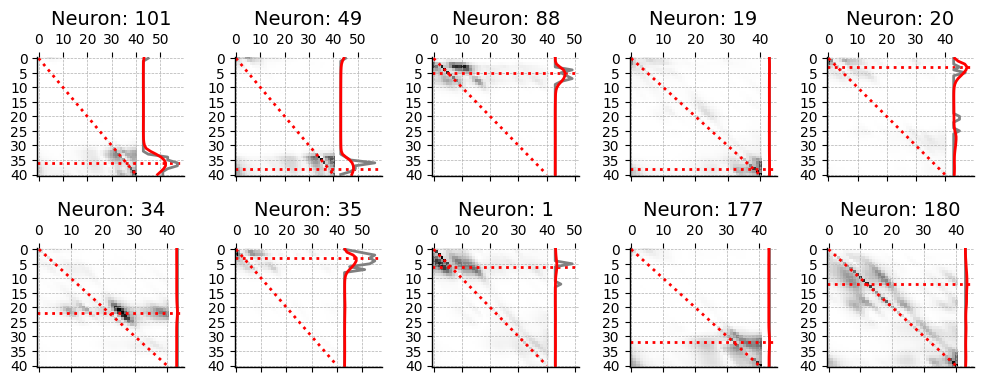

In [145]:
# Show saliency and reponse profiles for multiple neurons during the same flight path
target_flight_type = 14 # 25 # 32, 23
print(f'Saliency + response profile: session_target: {session_target}, target_flight_type: {target_flight_type}')
target_neuron_indices = np.argsort(corr_ood_dict[session_target])[::-1][:10]
ncols = 5
nrows = int(len(target_neuron_indices)/ncols)
fig, axs = plt.subplots(nrows=nrows, ncols=ncols, figsize=(ncols*2, nrows*2))
for ii in range(nrows):
    for jj in range(ncols):
        target_neuron_index = target_neuron_indices[ii*ncols+jj]

        # get the input (flight path) and its mask
        for session_name, session_data in dataloaders['test'].items():
            # print(session_name, session_data)
            if session_name == session_target:
                # we have only one batch of test data
                for batch_id, batch in enumerate(session_data):
                    X_val = batch[0].to(device)
                    y_val = batch[1].to(device)
                    mask_val = batch[2].to(device)
                    flight_type_index = batch.flight_type_index.detach().cpu().numpy()
                    target_flight_index = int(np.where(flight_type_index == target_flight_type)[0][0])
        X_val = X_val[target_flight_index][None, :, :]
        y_val = y_val[target_flight_index][None, :, :]
        mask_val = mask_val[target_flight_index][None, :]
        # model
        bat_former.load_state_dict(torch.load(model_name, map_location=device))
        # bat_former.load_state_dict(best_weights)
        bat_former = bat_former.to(device)
        bat_former.eval()
        # compute gradient
        grad_bat_former = Gradient_Bat_Transformer(
            model = bat_former,
            session_name = session_target, 
            X_val = X_val, # flight path; (torch.Size([1, num_of_time_points, 3]),
            y_val = y_val, # (torch.Size([1, num_of_time_points, num_of_neurons])
            mask_val = mask_val, # mask for the path; torch.Size([1, num_of_time_points]))
            target_neuron_index = target_neuron_index,
            trainer_config = trainer_config,
            device = device,
        )
        grad_bat_former.compute_feature_importance()
        
        axs[ii,jj].matshow(np.linalg.norm(np.array(grad_bat_former.gradient_list), axis=2), cmap='gray_r', aspect='auto')
        axs[ii,jj].axhline(y = np.argmax(grad_bat_former.response_pred), color='red', linestyle=':')
        axs[ii,jj].plot((0, grad_bat_former.unmask_T-1), (0, grad_bat_former.unmask_T-1), color='red', linestyle=':')
        axs[ii,jj].set_title(f'Neuron: {target_neuron_index}')
        axs[ii,jj].plot(grad_bat_former.response_val * 2 + grad_bat_former.unmask_T + 2, np.arange(grad_bat_former.unmask_T), color='gray')
        axs[ii,jj].plot(grad_bat_former.response_pred * 2 + grad_bat_former.unmask_T + 2, np.arange(grad_bat_former.unmask_T), color='r')
plt.tight_layout()

# Hierarchical clustering and orthogonality test

## Quick test

In [146]:
session_target = list(dataloaders['test'].keys())[4] # [4]
bat_former.load_state_dict(torch.load(model_name, map_location=device))
# bat_former.load_state_dict(best_weights)
bat_former = bat_former.to(device)
bat_former.eval()
readout_weights = bat_former.readouts[session_target][0].weight.detach().cpu().numpy()
print(f'session_target: {session_target}, readout_weights.shape: {readout_weights.shape}')

session_target: Dataset_3_29959_240403, readout_weights.shape: (191, 32)


In [147]:
thresh = 0.4
inds = np.where(corr_ood_dict[session_target] > thresh)[0]
# print(readout_weights[inds, :].shape)
weight_sim = cosine_similarity(readout_weights[inds, :])
print(f'weight_sim.shape: {weight_sim.shape}')

weight_sim.shape: (38, 38)


In [148]:
print(inds[np.where(np.abs(weight_sim)<0.001)[0]])
print(inds[np.where(np.abs(weight_sim)<0.001)[1]])
# plt.matshow(weight_sim, vmin=weight_sim.min(), vmax=-weight_sim.min(),cmap='bwr')
# plt.colorbar()

[  1 117 128 141]
[117   1 141 128]


## Analysis

In [149]:
thresh = 0.3
inds_sessions = {} # a dictionary of neuronal indices for each session
pType_sessions = {}  # pType arrays from meta_info_dict, filtered to selected units
readout_weight_sessions = [] # readout weights for selected units from all sessions
for session_target in list(dataloaders['test'].keys()):
    bat_former.load_state_dict(torch.load(model_name, map_location=device))
    bat_former = bat_former.to(device)
    bat_former.eval()
    readout_weights = bat_former.readouts[session_target][0].weight.detach().cpu().numpy()
    inds = np.where(corr_ood_dict[session_target] > thresh)[0]
    inds_sessions[session_target] = inds
    pType_sessions[session_target] = np.asarray(meta_info_dict['pType'][session_target])[inds]
    readout_weight_sessions.append(readout_weights[inds, :])
readout_weight_sessions = np.vstack(readout_weight_sessions)
# print(inds_sessions)
print(f'readout_weight_sessions.shape: {readout_weight_sessions.shape}') # (363, 256): 363 units, 256 features, aligned with inds_sessions_df rows

inds_sessions_df = pd.concat(
    [
        pd.DataFrame({
            "session_neuron_idx": inds,
            "session_name": session
        })
        for session, inds in inds_sessions.items()
    ],
    ignore_index=True
)
inds_sessions_df["global_neuron_idx"] = range(len(inds_sessions_df)) # a dataframe contains session_neuron_idx, session_name and global_neuron_idx

# Attach pType (putative cell type) aligned with inds_sessions_df rows
inds_sessions_df['pType'] = np.concatenate(
    [pType_sessions[s] for s in inds_sessions.keys()]
)
print(inds_sessions_df)

readout_weight_sessions.shape: (378, 32)
     session_neuron_idx            session_name  global_neuron_idx
0                     1  Dataset_3_14543_240419                  0
1                    40  Dataset_3_14543_240419                  1
2                    56  Dataset_3_14543_240419                  2
3                    57  Dataset_3_14543_240419                  3
4                    61  Dataset_3_14543_240419                  4
..                  ...                     ...                ...
373                  35  Dataset_1_32622_231010                373
374                  39  Dataset_1_32622_231010                374
375                  41  Dataset_1_32622_231010                375
376                  44  Dataset_1_32622_231010                376
377                  50  Dataset_1_32622_231010                377

[378 rows x 3 columns]


In [150]:
from scipy.spatial.distance import pdist, squareform
from scipy.cluster.hierarchy import linkage, dendrogram
from scipy.cluster.hierarchy import fcluster

X = np.copy(readout_weight_sessions)
X = X / np.linalg.norm(X, axis=1, keepdims=True)
# cosine distance = 1 - cosine similarity
dist_condensed = pdist(X, metric="cosine") # shape (363 * 362 / 2,)
dist_matrix = squareform(dist_condensed)  # shape (363, 363)
# Hierarchical clustering
Z = linkage(dist_condensed, method="average")
# The dendrogram returns the leaf order that optimally reflects the hierarchy
dendro = dendrogram(Z, no_plot=True)
order = dendro["leaves"]  # list of reordered neuron indices
# Reorder the distance matrix
dist_matrix_reordered = dist_matrix[np.ix_(order, order)]

In [ ]:
# Test whether readout cosine similarity is higher within the same putative cell type (pType)
# than across different types. Build a long-form DF of all unique pairs for easy seaborn plotting.
assert 'pType' in inds_sessions_df.columns, "Expected 'pType' column in inds_sessions_df"

# Cosine similarity from the row-normalized readout weights (X is already unit-norm above)
cos_sim_mat = X @ X.T  # (N, N)
N = cos_sim_mat.shape[0]
iu, ju = np.triu_indices(N, k=1)

pTypes = inds_sessions_df['pType'].values
sessions = inds_sessions_df['session_name'].values
# Coerce pType to plain python strings (entries may be numpy arrays/bytes/scalars)
def _pt_to_str(v):
    v = np.asarray(v).squeeze()
    if v.ndim == 0:
        v = v.item()
    if isinstance(v, bytes):
        v = v.decode()
    return str(v)
pTypes_str = np.array([_pt_to_str(v) for v in pTypes])
pt_i_str, pt_j_str = pTypes_str[iu], pTypes_str[ju]
pt_i, pt_j = pt_i_str, pt_j_str

# Order each pair so that (A, B) and (B, A) collapse to the same label
lo = np.where(pt_i_str <= pt_j_str, pt_i_str, pt_j_str)
hi = np.where(pt_i_str <= pt_j_str, pt_j_str, pt_i_str)
pair_label = np.char.add(np.char.add(lo, ' vs '), hi)

pair_df = pd.DataFrame({
    'i': iu,
    'j': ju,
    'pType_i': pt_i,
    'pType_j': pt_j,
    'pair': pair_label,
    'same_pType': pt_i == pt_j,
    'same_session': sessions[iu] == sessions[ju],
    'cosine_sim': cos_sim_mat[iu, ju],
})
print(f'pair_df: {len(pair_df)} pairs')
print(pair_df.groupby('pair')['cosine_sim']
      .agg(['count', 'mean', 'median'])
      .sort_values('mean', ascending=False))

from scipy.stats import mannwhitneyu
same = pair_df.loc[pair_df['same_pType'], 'cosine_sim'].values
diff = pair_df.loc[~pair_df['same_pType'], 'cosine_sim'].values
u, p = mannwhitneyu(same, diff, alternative='greater')
print(f"\nsame-pType mean={same.mean():.4f} (n={len(same)}) | "
      f"diff-pType mean={diff.mean():.4f} (n={len(diff)}) | "
      f"Mann-Whitney U={u:.0f}, p={p:.2e}")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.boxplot(data=pair_df, x='same_pType', y='cosine_sim',
            order=[True, False], ax=axes[0], showfliers=False)
sns.stripplot(data=pair_df, x='same_pType', y='cosine_sim',
              order=[True, False], ax=axes[0], color='k', alpha=0.15, size=2)
axes[0].set(xlabel='same pType', ylabel='cosine similarity',
            title=f'same vs different pType (one-sided MW p={p:.2e})')

pair_order = (pair_df.groupby('pair')['cosine_sim'].median()
              .sort_values(ascending=False).index.tolist())
sns.boxplot(data=pair_df, x='pair', y='cosine_sim',
            order=pair_order, ax=axes[1], showfliers=False)
axes[1].set(xlabel='pType pair', ylabel='cosine similarity',
            title='all pairwise pType contrasts')
axes[1].tick_params(axis='x', rotation=45)
for lbl in axes[1].get_xticklabels():
    lbl.set_ha('right')
plt.tight_layout()
plt.show()


In [151]:
# plt.figure(figsize=(7, 7))
# im = plt.imshow(dist_matrix_reordered, origin="lower")
# plt.colorbar(im, label="Cosine distance")
# plt.title("Reordered cosine distance matrix (hierarchical clustering)")
# plt.xlabel("Neuron (reordered)")
# plt.ylabel("Neuron (reordered)")
# plt.tight_layout()

In [152]:
# # plot dendrogram and reordered distance matrix
# fig = plt.figure(figsize=(7, 5))
# # Dendrogram
# ax_dendro = fig.add_axes([0.09, 0.1, 0.2, 0.8])
# dendrogram(
#     Z,
#     orientation="left",
#     # truncate_mode="level",
#     # p=4,                  # show only 4 levels
#     no_labels=True,
#     ax=ax_dendro
# )
# ax_dendro.set_xticks([])
# ax_dendro.set_yticks([])
# # Distance matrix (reordered)
# ax_mat = fig.add_axes([0.3, 0.1, 0.6, 0.8])
# im = ax_mat.matshow(dist_matrix_reordered, aspect="auto", origin="lower")
# ax_mat.set_xticks([])
# ax_mat.set_yticks([])
# # Colorbar
# ax_cb = fig.add_axes([0.92, 0.1, 0.02, 0.8])
# plt.colorbar(im, cax=ax_cb, label="Cosine distance")

In [153]:
# merge_distances = Z[:, 2]
# plt.figure(figsize=(5, 3))
# plt.plot(np.sort(merge_distances)[::-1])
# plt.xlabel("Merge step (largest → smallest)")
# plt.ylabel("Cosine distance")
# plt.title("Hierarchy merge distances")
# plt.tight_layout()

for t in [0.6, 0.7, 0.8, 0.9]:
    n = len(np.unique(fcluster(Z, t, criterion="distance")))
    print(f"t={t}: {n} clusters")

t=0.6: 113 clusters
t=0.7: 65 clusters
t=0.8: 30 clusters
t=0.9: 11 clusters


Text(0.5, 1.0, 'Cluster sizes (t = 0.9)')

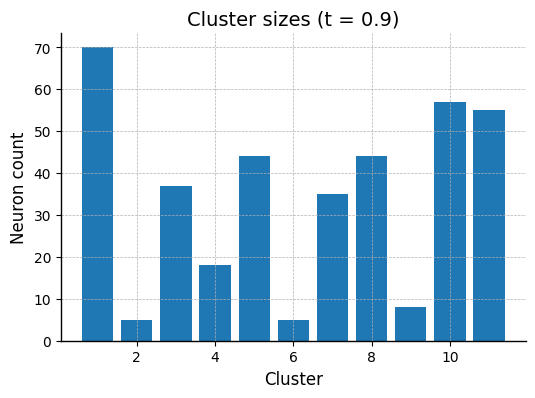

In [154]:
labels = fcluster(Z, 0.9, criterion="distance")
unique, counts = np.unique(labels, return_counts=True)

plt.bar(unique, counts)
plt.xlabel("Cluster")
plt.ylabel("Neuron count")
plt.title("Cluster sizes (t = 0.9)")

Text(0.5, 1.0, 'Cluster composition across sessions')

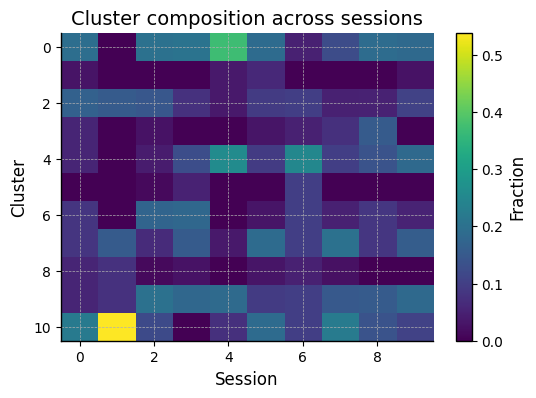

In [155]:
inds_sessions_df["cluster"] = labels
ct = pd.crosstab(inds_sessions_df["cluster"], inds_sessions_df["session_name"], normalize="columns")

plt.imshow(ct, aspect="auto")
plt.colorbar(label="Fraction")
plt.xlabel("Session")
plt.ylabel("Cluster")
plt.title("Cluster composition across sessions")

In [156]:
# Reorder neuron metadata
inds_sessions_df_reordered = inds_sessions_df.iloc[order].reset_index(drop=True)
inds_sessions_df_reordered

,session_neuron_idx,session_name,global_neuron_idx,cluster
0,287,Dataset_3_14543_240419,26,1
1,130,Dataset_3_29959_240403,156,1
2,176,Dataset_3_14543_240419,17,1
3,51,Dataset_3_14543_240420,44,1
4,158,Dataset_3_29959_240403,166,1
...,...,...,...,...
373,8,Dataset_3_14543_240421,60,11
374,21,Dataset_1_32622_231010,371,11
375,1,Dataset_3_29959_240404,178,11
376,100,Dataset_3_14543_240420,56,11


In [157]:
tester = OrthogonalityPermutationTest(
    X=readout_weight_sessions,
    df=inds_sessions_df,
    session_name=list(dataloaders['test'].keys())[4],
    n_perm=1000,
    random_state=0,
    null_model='shuffle_weights',
)
sig_df = tester.significant_pairs_with_session_indices(alpha=0.05)
sig_df

,session_neuron_idx_1,session_neuron_idx_2,p_value,cosine_distance
0,1,7,0.014985,0.996264
1,1,74,0.046953,1.009211
2,1,117,0.005994,0.999363
3,1,138,0.026973,1.008284
4,1,141,0.022977,0.994663
...,...,...,...,...
64,141,184,0.043956,0.991861
65,146,160,0.010989,1.002813
66,146,161,0.025974,0.992404
67,155,158,0.010989,0.998032


In [158]:
sig_df[sig_df['session_neuron_idx_1'] == 20]

,session_neuron_idx_1,session_neuron_idx_2,p_value,cosine_distance
14,20,23,0.038961,0.991619
15,20,58,0.034965,0.989882
16,20,88,0.007992,0.998631
17,20,89,0.006993,0.998379
18,20,106,0.048951,0.987628
19,20,135,0.049950,0.990323


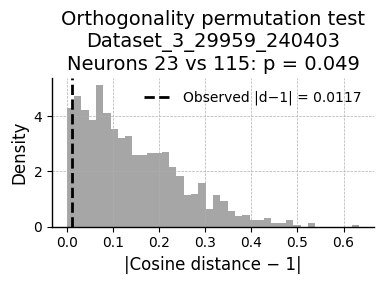

In [159]:
row = sig_df.iloc[21]
tester.plot_null_vs_observed(
    session_neuron_idx_1=row["session_neuron_idx_1"],
    session_neuron_idx_2=row["session_neuron_idx_2"],
)

# GLM model with 3D cosine basis

In [175]:
from digitalbat.models.glm import Bat_GLM


def create_cosine_bumps_torch(x, centers, width):
    """Raised cosine bumps in PyTorch.

    x: (...,) tensor of positions
    centers: (K,) tensor of bump centers
    width: scalar bump width

    returns: (..., K) tensor
    """
    diff = x.unsqueeze(-1) - centers
    return (torch.cos(2 * np.pi * diff / width) * 0.5 + 0.5) * (diff.abs() < width / 2).float()


class GLM_3DCosineBasis(nn.Module):
    """3D tensor-product cosine basis expansion + session-wise linear GLM.

    Equivalent to GLM_PyTorch but with session-wise heads, using 3D
    raised cosine bumps over (x, y, z) z-scored position as the design matrix.
    """
    def __init__(
        self,
        output_dim_dict,
        n_bases_per_dim=8,
        pos_range=(-3.0, 3.0),
        width_to_spacing_ratio=4,
        activation='exp',
    ):
        super().__init__()
        centers = torch.linspace(pos_range[0], pos_range[1], n_bases_per_dim)
        spacing = (pos_range[1] - pos_range[0]) / (n_bases_per_dim - 1)
        self.register_buffer('centers', centers)
        self.width = width_to_spacing_ratio * spacing
        self.n_bases_per_dim = n_bases_per_dim
        n_features = n_bases_per_dim ** 3
        self.glm = Bat_GLM(
            input_dim=n_features,
            output_dim_dict=output_dim_dict,
            activation=activation,
        )

    def forward(self, session_name, x, *args, **kwargs):
        # x: (N, T, behavior_dim) — first 3 dims = x, y, z (z-scored by dataloader)
        b_x = create_cosine_bumps_torch(x[..., 0], self.centers, self.width)  # (N, T, K)
        b_y = create_cosine_bumps_torch(x[..., 1], self.centers, self.width)
        b_z = create_cosine_bumps_torch(x[..., 2], self.centers, self.width)
        bases = (
            b_x.unsqueeze(-1).unsqueeze(-1)
            * b_y.unsqueeze(-2).unsqueeze(-1)
            * b_z.unsqueeze(-2).unsqueeze(-2)
        )  # (N, T, K, K, K)
        return self.glm(session_name, bases.flatten(-3))  # (N, T, K**3)


glm_config = dict(
    output_dim_dict=unit_num_dict,
    n_bases_per_dim=16,
    pos_range=(-3.0, 3.0),
    width_to_spacing_ratio=4,
    activation='exp',
)
bat_glm = GLM_3DCosineBasis(**glm_config)
bat_glm


GLM_3DCosineBasis(
  (glm): Bat_GLM(
    (readouts): ModuleDict(
      (Dataset_3_14543_240419): Linear(in_features=4096, out_features=289, bias=True)
      (Dataset_3_14543_240420): Linear(in_features=4096, out_features=126, bias=True)
      (Dataset_3_14543_240421): Linear(in_features=4096, out_features=100, bias=True)
      (Dataset_3_29959_240402): Linear(in_features=4096, out_features=317, bias=True)
      (Dataset_3_29959_240403): Linear(in_features=4096, out_features=191, bias=True)
      (Dataset_3_29959_240404): Linear(in_features=4096, out_features=190, bias=True)
      (Dataset_2_14445_231208): Linear(in_features=4096, out_features=237, bias=True)
      (Dataset_2_14445_231209): Linear(in_features=4096, out_features=168, bias=True)
      (Dataset_1_32622_231009): Linear(in_features=4096, out_features=95, bias=True)
      (Dataset_1_32622_231010): Linear(in_features=4096, out_features=54, bias=True)
    )
  )
)

### Visualize 3D cosine basis

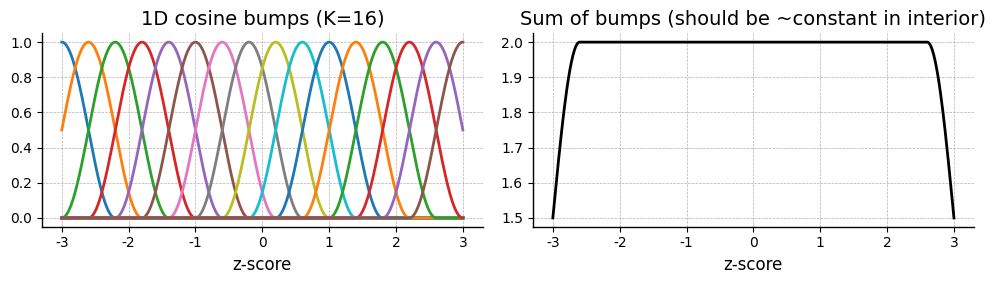

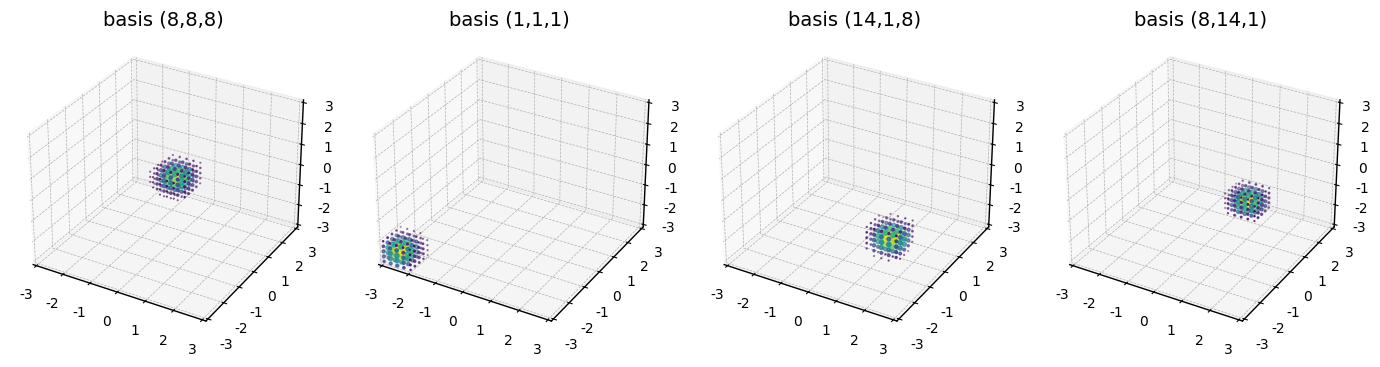

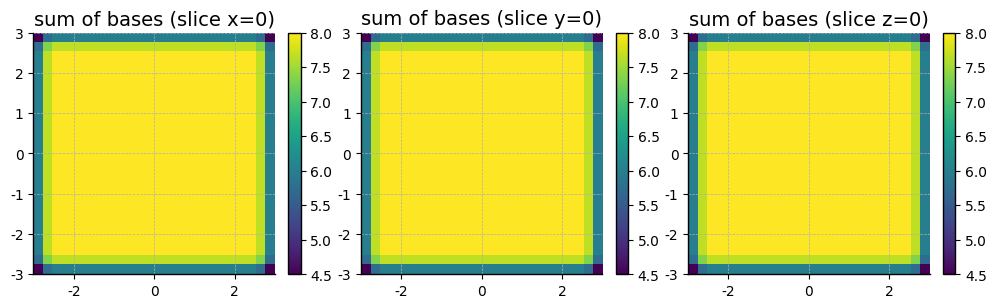

Real positions: shape=(326, 3), x∈[-1.77,1.49], y∈[-2.12,1.50], z∈[-3.58,2.01]
Bases on real data: per-sample sum mean=7.694 (should be ~1 inside the tiled region), max=0.991


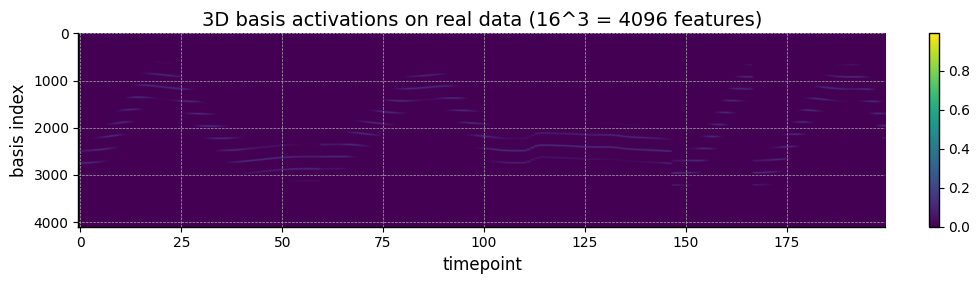

In [176]:
# Sanity check the 3D raised cosine basis used by the GLM.
# 1) 1D cosine bumps along one axis (should tile evenly — sum ≈ constant in interior).
# 2) A few selected 3D basis functions shown as 3D scatter (point size ∝ basis value).
# 3) Sum-of-bases slices (should be ~constant in the interior of the tiled cube).
# 4) Bases evaluated on real (z-scored) test positions.

centers = bat_glm.centers.cpu().numpy()
width = bat_glm.width
K = bat_glm.n_bases_per_dim
lo, hi = float(centers[0]), float(centers[-1])

# --- (1) 1D bumps along one axis ---
xs = torch.linspace(lo, hi, 500)
b1d = create_cosine_bumps_torch(xs, bat_glm.centers, width).cpu().numpy()
fig, axes = plt.subplots(1, 2, figsize=(10, 3))
axes[0].plot(xs.numpy(), b1d)
axes[0].set(title=f'1D cosine bumps (K={K})', xlabel='z-score')
axes[1].plot(xs.numpy(), b1d.sum(axis=1), 'k')
axes[1].set(title='Sum of bumps (should be ~constant in interior)', xlabel='z-score')
plt.tight_layout()
plt.show()

# --- (2) Selected 3D basis functions over a 3D grid ---
N_GRID = 25
g = torch.linspace(lo, hi, N_GRID)
X3, Y3, Z3 = torch.meshgrid(g, g, g, indexing='ij')
grid = torch.stack([X3.flatten(), Y3.flatten(), Z3.flatten()], dim=-1)
bx = create_cosine_bumps_torch(grid[:, 0], bat_glm.centers, width)
by = create_cosine_bumps_torch(grid[:, 1], bat_glm.centers, width)
bz = create_cosine_bumps_torch(grid[:, 2], bat_glm.centers, width)
bases_grid = (bx.unsqueeze(-1).unsqueeze(-1) * by.unsqueeze(-2).unsqueeze(-1) * bz.unsqueeze(-2).unsqueeze(-2)).flatten(-3).cpu().numpy()

chosen = [
    (K // 2, K // 2, K // 2),
    (1, 1, 1),
    (K - 2, 1, K // 2),
    (K // 2, K - 2, 1),
]
fig = plt.figure(figsize=(14, 3.5))
for i, (ix, iy, iz) in enumerate(chosen):
    flat_idx = ix * K * K + iy * K + iz
    vals = bases_grid[:, flat_idx]
    keep = vals > 0.01
    ax = fig.add_subplot(1, 4, i + 1, projection='3d')
    ax.scatter(
        grid[keep, 0].cpu(), grid[keep, 1].cpu(), grid[keep, 2].cpu(),
        c=vals[keep], s=20 * vals[keep], cmap='viridis',
    )
    ax.set(title=f'basis ({ix},{iy},{iz})', xlim=(lo, hi), ylim=(lo, hi), zlim=(lo, hi))
plt.tight_layout()
plt.show()

# Sum-of-bases slices
total = bases_grid.sum(axis=1).reshape(N_GRID, N_GRID, N_GRID)
mid = N_GRID // 2
fig, axes = plt.subplots(1, 3, figsize=(10, 3))
for ax, sl, name in zip(axes, [total[mid], total[:, mid], total[:, :, mid]], ['x=0', 'y=0', 'z=0']):
    im = ax.imshow(sl, extent=[lo, hi, lo, hi], origin='lower')
    ax.set_title(f'sum of bases (slice {name})')
    plt.colorbar(im, ax=ax, fraction=0.046)
plt.tight_layout()
plt.show()

# --- (3) Apply on real (z-scored) test positions ---
session_name = list(dataloaders['test'].keys())[0]
batch = next(iter(dataloaders['test'][session_name]))
X_real = batch[0]
mask_real = batch[2]
xyz = X_real[..., :3][mask_real == 1.0]
print(f"Real positions: shape={tuple(xyz.shape)}, "
      f"x∈[{xyz[:,0].min():.2f},{xyz[:,0].max():.2f}], "
      f"y∈[{xyz[:,1].min():.2f},{xyz[:,1].max():.2f}], "
      f"z∈[{xyz[:,2].min():.2f},{xyz[:,2].max():.2f}]")

with torch.no_grad():
    bx = create_cosine_bumps_torch(xyz[:, 0], bat_glm.centers, width)
    by = create_cosine_bumps_torch(xyz[:, 1], bat_glm.centers, width)
    bz = create_cosine_bumps_torch(xyz[:, 2], bat_glm.centers, width)
    bases_real = (bx.unsqueeze(-1).unsqueeze(-1) * by.unsqueeze(-2).unsqueeze(-1) * bz.unsqueeze(-2).unsqueeze(-2)).flatten(-3)

print(f"Bases on real data: per-sample sum mean={bases_real.sum(dim=1).mean():.3f} "
      f"(should be ~1 inside the tiled region), max={bases_real.max():.3f}")

fig, ax = plt.subplots(figsize=(10, 3))
im = ax.imshow(bases_real[:200].cpu().numpy().T, aspect='auto', cmap='viridis')
ax.set(xlabel='timepoint', ylabel='basis index',
       title=f'3D basis activations on real data ({K}^3 = {K**3} features)')
plt.colorbar(im, ax=ax, fraction=0.02)
plt.tight_layout()
plt.show()


## Training

Testing weight_decay=0


Training:   0%|          | 0/1000 [00:00<?, ?it/s]

Training:  16%|█▌        | 162/1000 [00:34<02:56,  4.74it/s]


Early stopping at epoch 163 (no improvement for 100 epochs)
  Final val score (median FDE, filtered): -0.0686
Testing weight_decay=1e-05


Training:  11%|█         | 106/1000 [00:22<03:12,  4.63it/s]


...

Early stopping at epoch 103 (no improvement for 100 epochs)
  Final val score (median FDE, filtered): -0.0506
Testing weight_decay=0.01


Training:  10%|█         | 102/1000 [00:22<03:15,  4.58it/s]


Early stopping at epoch 103 (no improvement for 100 epochs)
  Final val score (median FDE, filtered): -0.0505
Testing weight_decay=0.1


Training:  10%|█         | 100/1000 [00:21<03:16,  4.58it/s]


Early stopping at epoch 101 (no improvement for 100 epochs)
  Final val score (median FDE, filtered): -0.0505

Best weight_decay: 0.0001 with val score: -0.0496


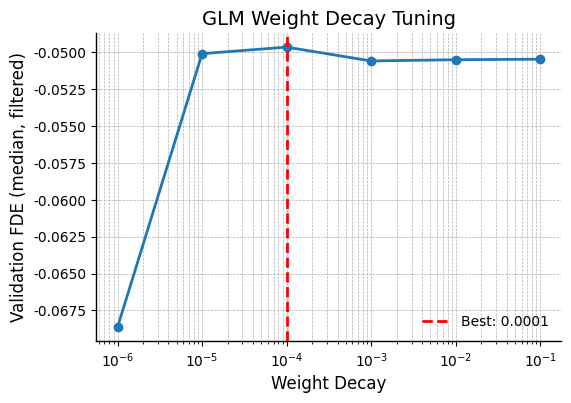

In [177]:
# Hyperparameter tuning for weight_decay using validation set
from copy import deepcopy

weight_decay_candidates = [0, 1e-5, 1e-4, 1e-3, 1e-2, 1e-1]

best_wd = None
best_val_score = -np.inf
best_weights_overall = None
wd_results = []

for wd in weight_decay_candidates:
    print(f'Testing weight_decay={wd}')
    
    # Create model, warm-start from previous best if available
    glm_tune = GLM_3DCosineBasis(**glm_config)
    if best_weights_overall is not None:
        glm_tune.load_state_dict(deepcopy(best_weights_overall))
    
    # Train with this weight_decay
    tune_config = dict(
        model=glm_tune,
        dataloaders=dataloaders,
        device=device,
        n_epochs=1000,
        lr=0.01,
        weight_decay=wd,
        loss_fn=nn.PoissonNLLLoss(log_input=False),
        valid_fn=poisson_fde_population,
        valid_stat='median',
        early_stopping_patience=20,
        save_model=False,
    )
    val_score, weights, val_scores = bat_former_trainer(**tune_config)
    wd_results.append({'weight_decay': wd, 'val_score': val_score})
    print(f'  Final val score (median FDE, filtered): {val_score:.4f}')
    
    if val_score > best_val_score:
        best_val_score = val_score
        best_wd = wd
        best_weights_overall = deepcopy(weights)

print(f'\nBest weight_decay: {best_wd} with val score: {best_val_score:.4f}')

# Plot results
fig, ax = plt.subplots(figsize=(6, 4))
wds = [r['weight_decay'] for r in wd_results]
scores = [r['val_score'] for r in wd_results]
ax.semilogx([w if w > 0 else 1e-6 for w in wds], scores, 'o-')
ax.axvline(best_wd if best_wd > 0 else 1e-6, color='r', linestyle='--', label=f'Best: {best_wd}')
ax.set_xlabel('Weight Decay')
ax.set_ylabel('Validation FDE (median, filtered)')
ax.set_title('GLM Weight Decay Tuning')
ax.legend()
plt.show()

In [216]:
# Set best_wd here if skipping tuning loop
best_wd = best_wd if 'best_wd' in dir() else 0.0

# Train final GLM with best weight_decay
bat_glm = GLM_3DCosineBasis(**glm_config)  # Fresh model

glm_trainer_config = dict(
    model=bat_glm,
    dataloaders=dataloaders,
    device=device,
    n_epochs=500,
    lr=0.01,
    weight_decay=best_wd,
    loss_fn=nn.PoissonNLLLoss(log_input=False),
    valid_fn=poisson_fde_population,
    valid_stat='median',
    early_stopping_patience=20,
    save_model=True,
    model_name=f"./out/bat_glm_seed_{seed}_wd_{best_wd}.pth",
)

# best_acc, best_weights, acc_vals = bat_former_trainer(**glm_trainer_config)
# print(f'Final model trained with weight_decay={best_wd}, best val score: {best_acc:.4f}')

# fig, axes = plt.subplots(nrows=1, ncols=1, figsize=(4, 3))
# axes.plot(acc_vals)
# axes.set_title(f"Best: {best_acc:.4f}")
# axes.set_xlabel("Epoch")
# axes.set_ylabel("FDE (median, filtered)")
# plt.show()

## Evaluation

### Correlation

In [220]:
# Load trained GLM
glm_model_name = f'./out/bat_glm_seed_{seed}_wd_{best_wd}.pth'
bat_glm.load_state_dict(torch.load(glm_model_name, map_location=device))
bat_glm = bat_glm.to(device)

# Evaluate GLM with same metrics
glm_results = {}
for metric_name, valid_fn in metrics.items():
    for flight_filter in flight_filters:
        key = f"{metric_name}_{flight_filter or 'all'}"
        glm_results[key] = evaluate_model(
            bat_glm, dataloaders, valid_fn, device,
            flight_filter=flight_filter, meta_info_dict=meta_info_dict
        )
        all_scores = np.hstack([v for v in glm_results[key].values() if len(v) > 0])
        stat = np.nanmedian if 'fde' in key else np.nanmean
        print(f"GLM {key}: {stat(all_scores):.4f}")

GLM corr_all: 0.1653
GLM corr_ood: 0.0712
GLM corr_indomain: 0.2136
GLM fde_all: -0.0533
GLM fde_ood: -0.3717
GLM fde_indomain: 0.0037


In [224]:
# Build comparison DataFrame with all subsets
rows = []
for session_name in transformer_results['corr_all'].keys():
    # Extract 5-digit bat ID from session name (e.g., 'Dataset_3_14543_240419' -> '14543')
    bat_id = re.search(r'_(\d{5})_', session_name).group(1)
    # Extract date from last 6 digits (YYMMDD format)
    date_str = session_name[-6:]
    date = datetime.strptime(date_str, '%y%m%d').date()
    n_units = len(transformer_results['corr_all'][session_name])
    
    for i in range(n_units):
        for subset in ['all', 'ood', 'indomain']:
            corr_key = f'corr_{subset}'
            fde_key = f'fde_{subset}'
            # Transformer
            rows.append({
                'session': session_name, 'bat': bat_id, 'date': date, 'unit': i,
                'model': 'Transformer', 'metric': 'Correlation', 'subset': subset,
                'value': transformer_results[corr_key][session_name][i]
            })
            rows.append({
                'session': session_name, 'bat': bat_id, 'date': date, 'unit': i,
                'model': 'Transformer', 'metric': 'FDE', 'subset': subset,
                'value': max(transformer_results[fde_key][session_name][i], -1)
            })
            # GLM
            rows.append({
                'session': session_name, 'bat': bat_id, 'date': date, 'unit': i,
                'model': 'GLM', 'metric': 'Correlation', 'subset': subset,
                'value': glm_results[corr_key][session_name][i]
            })
            rows.append({
                'session': session_name, 'bat': bat_id, 'date': date, 'unit': i,
                'model': 'GLM', 'metric': 'FDE', 'subset': subset,
                'value': max(glm_results[fde_key][session_name][i], -1)
            })

df = pd.DataFrame(rows)
df

,session,bat,date,unit,model,metric,subset,value
0,Dataset_3_14543_240419,14543,2024-04-19,0,Transformer,Correlation,all,0.227134
1,Dataset_3_14543_240419,14543,2024-04-19,0,Transformer,FDE,all,0.394640
2,Dataset_3_14543_240419,14543,2024-04-19,0,GLM,Correlation,all,-0.011981
3,Dataset_3_14543_240419,14543,2024-04-19,0,GLM,FDE,all,-1.000000
4,Dataset_3_14543_240419,14543,2024-04-19,0,Transformer,Correlation,ood,0.293410
...,...,...,...,...,...,...,...,...
21199,Dataset_1_32622_231010,32622,2023-10-10,53,GLM,FDE,ood,0.170528
21200,Dataset_1_32622_231010,32622,2023-10-10,53,Transformer,Correlation,indomain,0.101573
21201,Dataset_1_32622_231010,32622,2023-10-10,53,Transformer,FDE,indomain,0.007197
21202,Dataset_1_32622_231010,32622,2023-10-10,53,GLM,Correlation,indomain,-0.001935


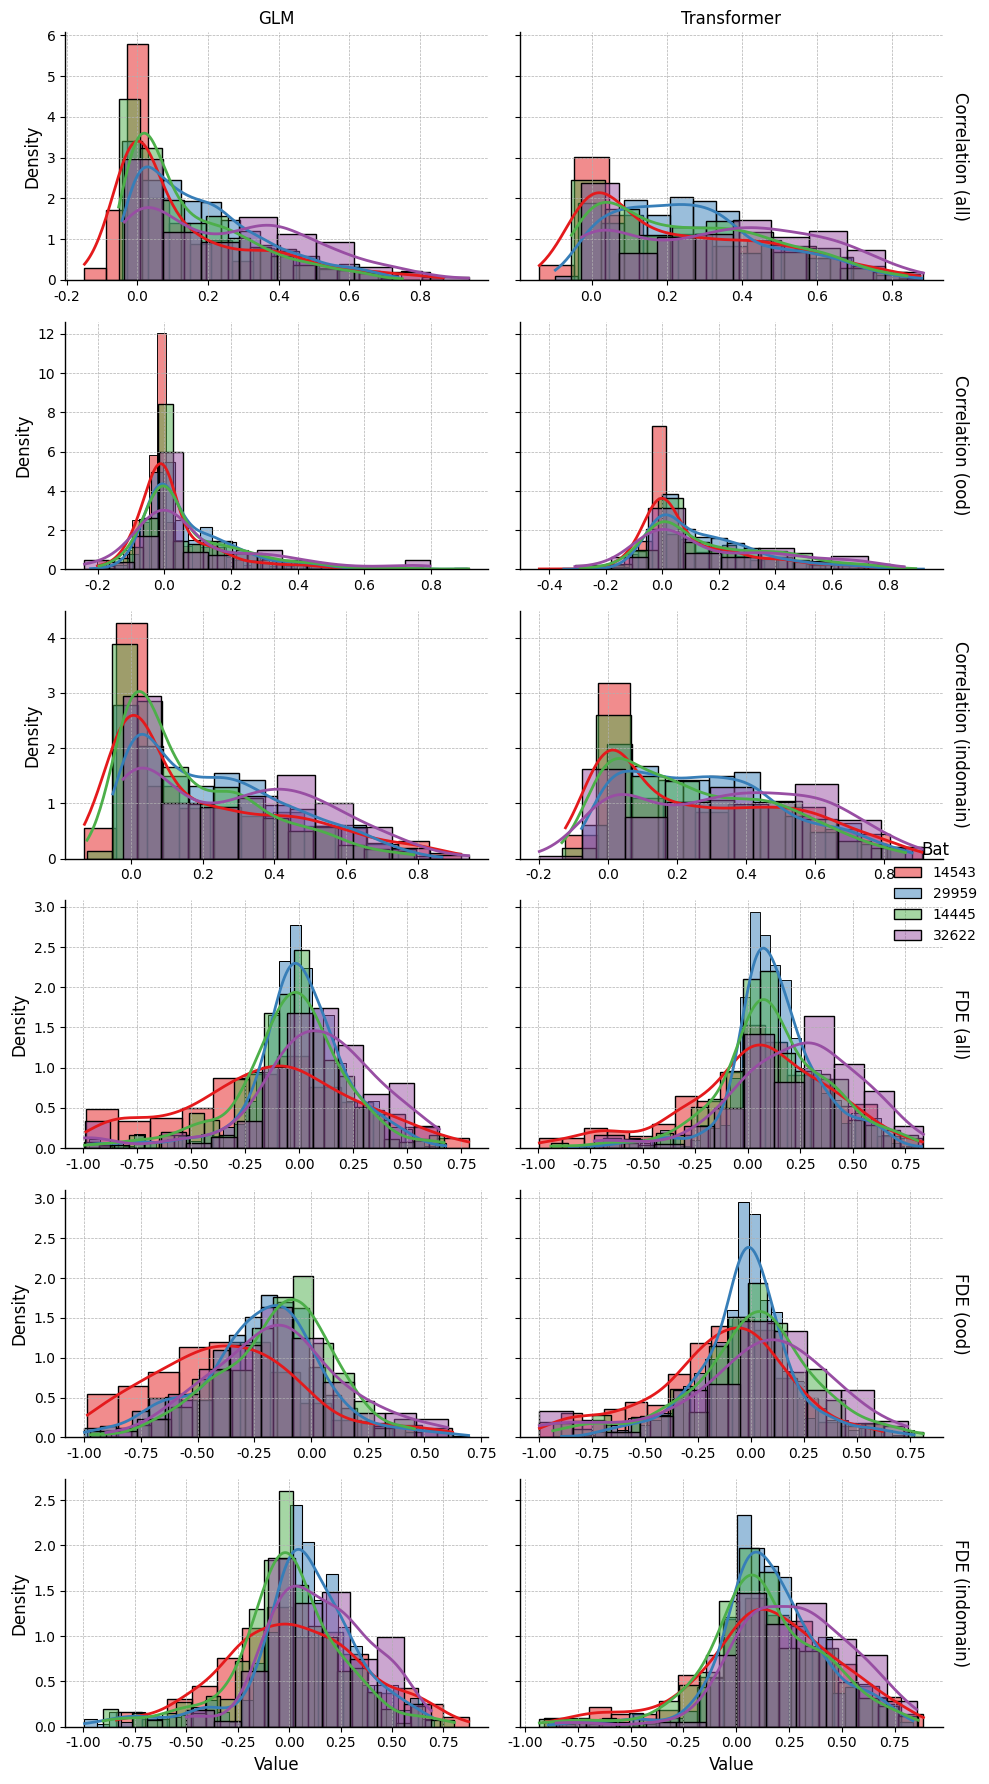

In [230]:
# Plot all sessions: col=model, row=metric+subset, hue=bat
df['row_label'] = df['metric'] + ' (' + df['subset'] + ')'

row_order = [
    'Correlation (all)', 'Correlation (ood)', 'Correlation (indomain)',
    'FDE (all)', 'FDE (ood)', 'FDE (indomain)'
]

# Filter out FDE values <= -1
df_filtered = df[~((df['metric'] == 'FDE') & (df['value'] <= -1))]

g = sns.FacetGrid(
    df_filtered,
    col='model',
    row='row_label',
    hue='bat',
    col_order=['GLM', 'Transformer'],
    row_order=row_order,
    height=3,
    aspect=1.5,
    palette='Set1',
    sharex=False,
    sharey='row',
    margin_titles=True
)

g.map(sns.histplot, 'value', kde=True, alpha=0.5, stat='density', common_norm=False)
g.set_axis_labels('Value', 'Density')
g.set_titles(col_template='{col_name}', row_template='{row_name}')
g.add_legend(title='Bat')
plt.tight_layout()
plt.show()

Wilcoxon signed-rank test (H1: Transformer > GLM)

==================== Subset: all ====================
--- Correlation ---
Pooled (all units):
  All units: n=1767, median diff=0.0792, p=9.03e-156 ***
--- FDE ---
Pooled (all units):
  All units: n=1505, median diff=0.1367, p=1.00e-156 ***

==================== Subset: ood ====================
--- Correlation ---
Pooled (all units):
  All units: n=1767, median diff=0.0264, p=1.64e-67 ***
--- FDE ---
Pooled (all units):
  All units: n=1200, median diff=0.1970, p=9.12e-90 ***

==================== Subset: indomain ====================
--- Correlation ---
Pooled (all units):
  All units: n=1767, median diff=0.0454, p=5.35e-103 ***
--- FDE ---
Pooled (all units):
  All units: n=1516, median diff=0.0897, p=1.08e-117 ***

Summary (pooled):
     metric   subset    n  median_diff             p
Correlation      all 1767     0.079239 9.028714e-156
        FDE      all 1505     0.136654 1.004348e-156
Correlation      ood 1767     0.026366  1.6406

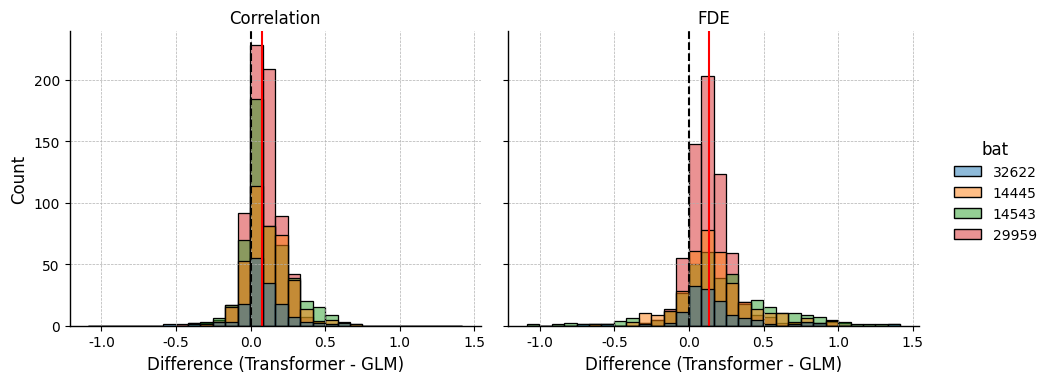

In [228]:
# Wilcoxon signed-rank test: GLM vs Transformer improvement (per subset)
from scipy.stats import wilcoxon

def wilcoxon_test(glm_scores, transformer_scores, name):
    """Run Wilcoxon signed-rank test and print results."""
    mask = ~(np.isnan(glm_scores) | np.isnan(transformer_scores))
    glm, tf = glm_scores[mask], transformer_scores[mask]
    if len(glm) < 10:
        print(f"{name}: n={len(glm)} (too few samples)")
        return None
    stat, p = wilcoxon(glm, tf, alternative='less')
    median_diff = np.median(tf - glm)
    print(f"{name}: n={len(glm)}, median diff={median_diff:.4f}, p={p:.2e} {'***' if p<0.001 else '**' if p<0.01 else '*' if p<0.05 else ''}")
    return {'name': name, 'n': len(glm), 'median_diff': median_diff, 'p': p}

print("Wilcoxon signed-rank test (H1: Transformer > GLM)")
print("=" * 50)

stats_results = []
for subset in ['all', 'ood', 'indomain']:
    print(f"\n{'='*20} Subset: {subset} {'='*20}")
    df_subset = df_filtered[df_filtered['subset'] == subset]
    
    for metric in ['Correlation', 'FDE']:
        df_pivot = df_subset[df_subset['metric'] == metric].pivot_table(
            index=['session', 'bat', 'date', 'unit'], columns='model', values='value'
        ).reset_index()
        
        print(f"--- {metric} ---")
        print("Pooled (all units):")
        result = wilcoxon_test(df_pivot['GLM'].values, df_pivot['Transformer'].values, "  All units")
        if result:
            stats_results.append({**result, 'metric': metric, 'subset': subset, 'level': 'pooled'})

df_stats = pd.DataFrame(stats_results)
print("\nSummary (pooled):")
print(df_stats[df_stats['level'] == 'pooled'][['metric', 'subset', 'n', 'median_diff', 'p']].to_string(index=False))

# Compute differences and plot histogram (for 'all' subset)
df_all = df_filtered[df_filtered['subset'] == 'all']
df_diff = df_all.pivot_table(
    index=['session', 'bat', 'date', 'unit', 'metric'], columns='model', values='value'
).reset_index()
df_diff['diff'] = df_diff['Transformer'] - df_diff['GLM']

g = sns.displot(
    data=df_diff, x='diff', hue='bat', col='metric', kind='hist',
    bins=30, alpha=0.5, height=4, aspect=1.2
)
for ax in g.axes.flat:
    ax.axvline(0, color='black', linestyle='--', lw=1.5)
    ax.axvline(df_diff[df_diff['metric'] == ax.get_title().split()[-1]]['diff'].median(), 
               color='red', linestyle='-', lw=1.5)
g.set_axis_labels('Difference (Transformer - GLM)', 'Count')
g.set_titles('{col_name}')
plt.show()